Patients represented in TFx metasheet: 262
Patients with a selected first draw: 262
Griffin samples loaded: 769

Metastatic ER status at first draw:
  ER-positive: 166
  ER-negative: 53
  ER-unknown: 43
  Total: 262

Samples with matched Griffin results: 262
Samples with matched blood-draw day: 262

Adjusted model results:
TF        Metric                 N     Beta ER+           P       FDR Q Status
----------------------------------------------------------------------------------------------------
ESR1      mean_coverage        211     -0.00417     0.00527      0.0119 OK
ESR1      central_coverage     211     -0.01054      0.0806       0.131 OK
ESR1      amplitude            211      0.11551      0.0649       0.357 OK
FOXA1     mean_coverage        211     -0.00618     0.00651      0.0119 OK
FOXA1     central_coverage     211     -0.01320      0.0949       0.131 OK
FOXA1     amplitude            211      0.02333       0.787       0.889 OK
GATA3     mean_coverage        211     -0.006

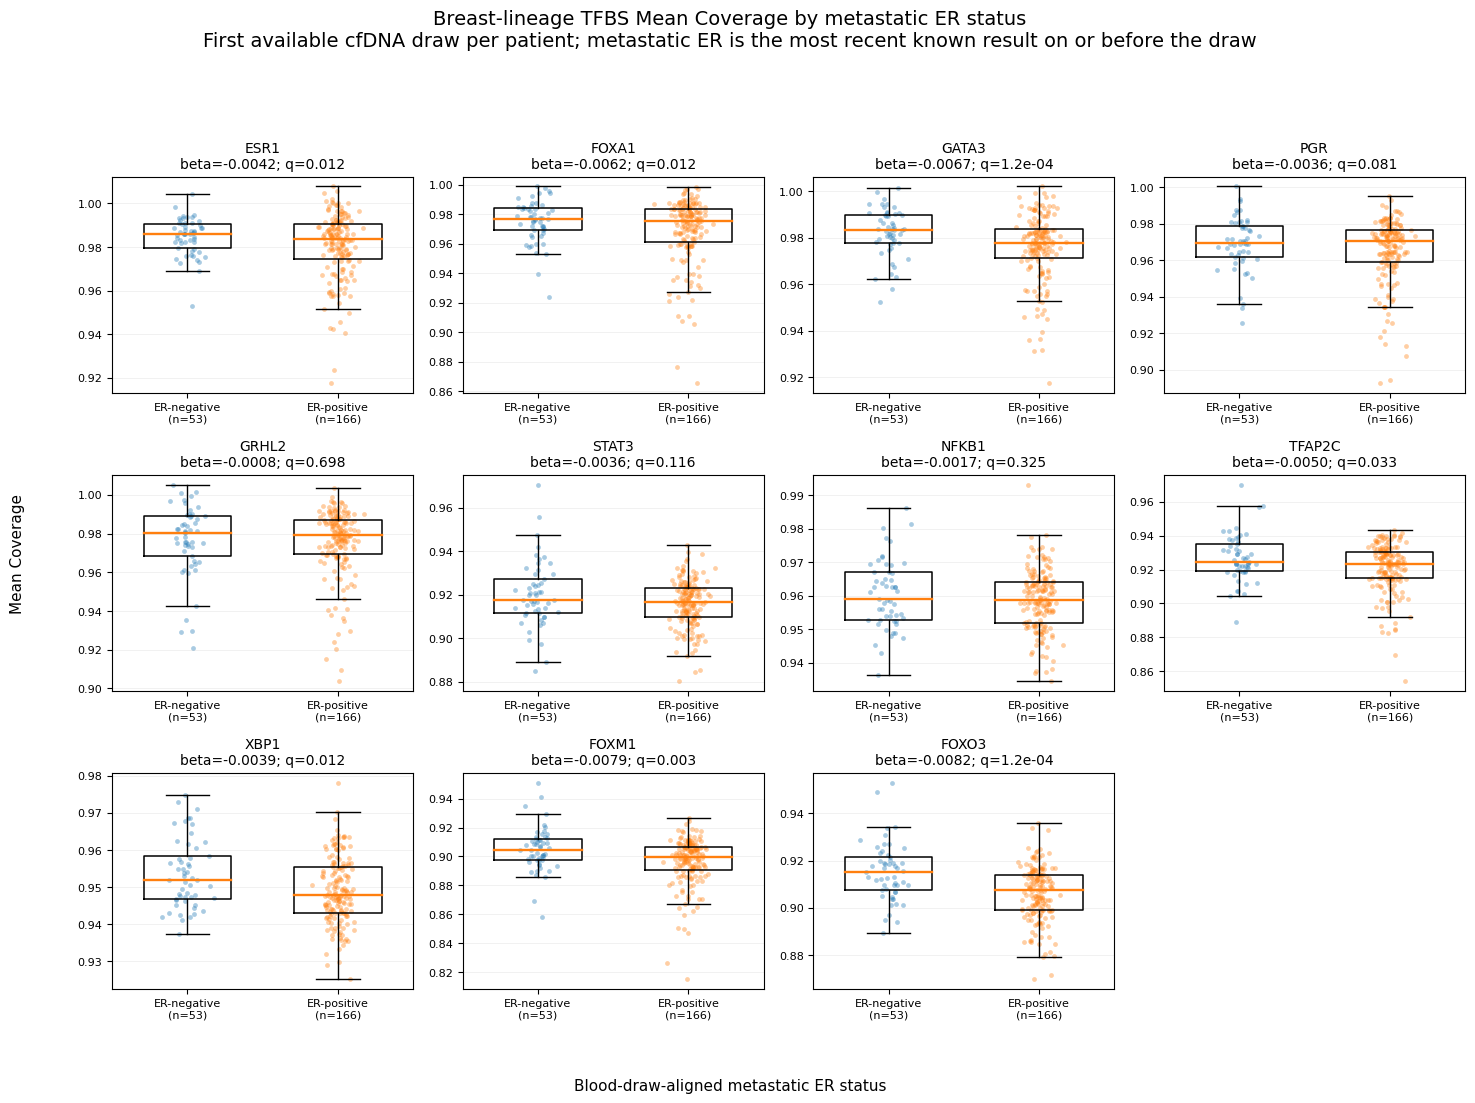

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Faceted_central_coverage_ER_positive_vs_negative.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Faceted_central_coverage_ER_positive_vs_negative.pdf


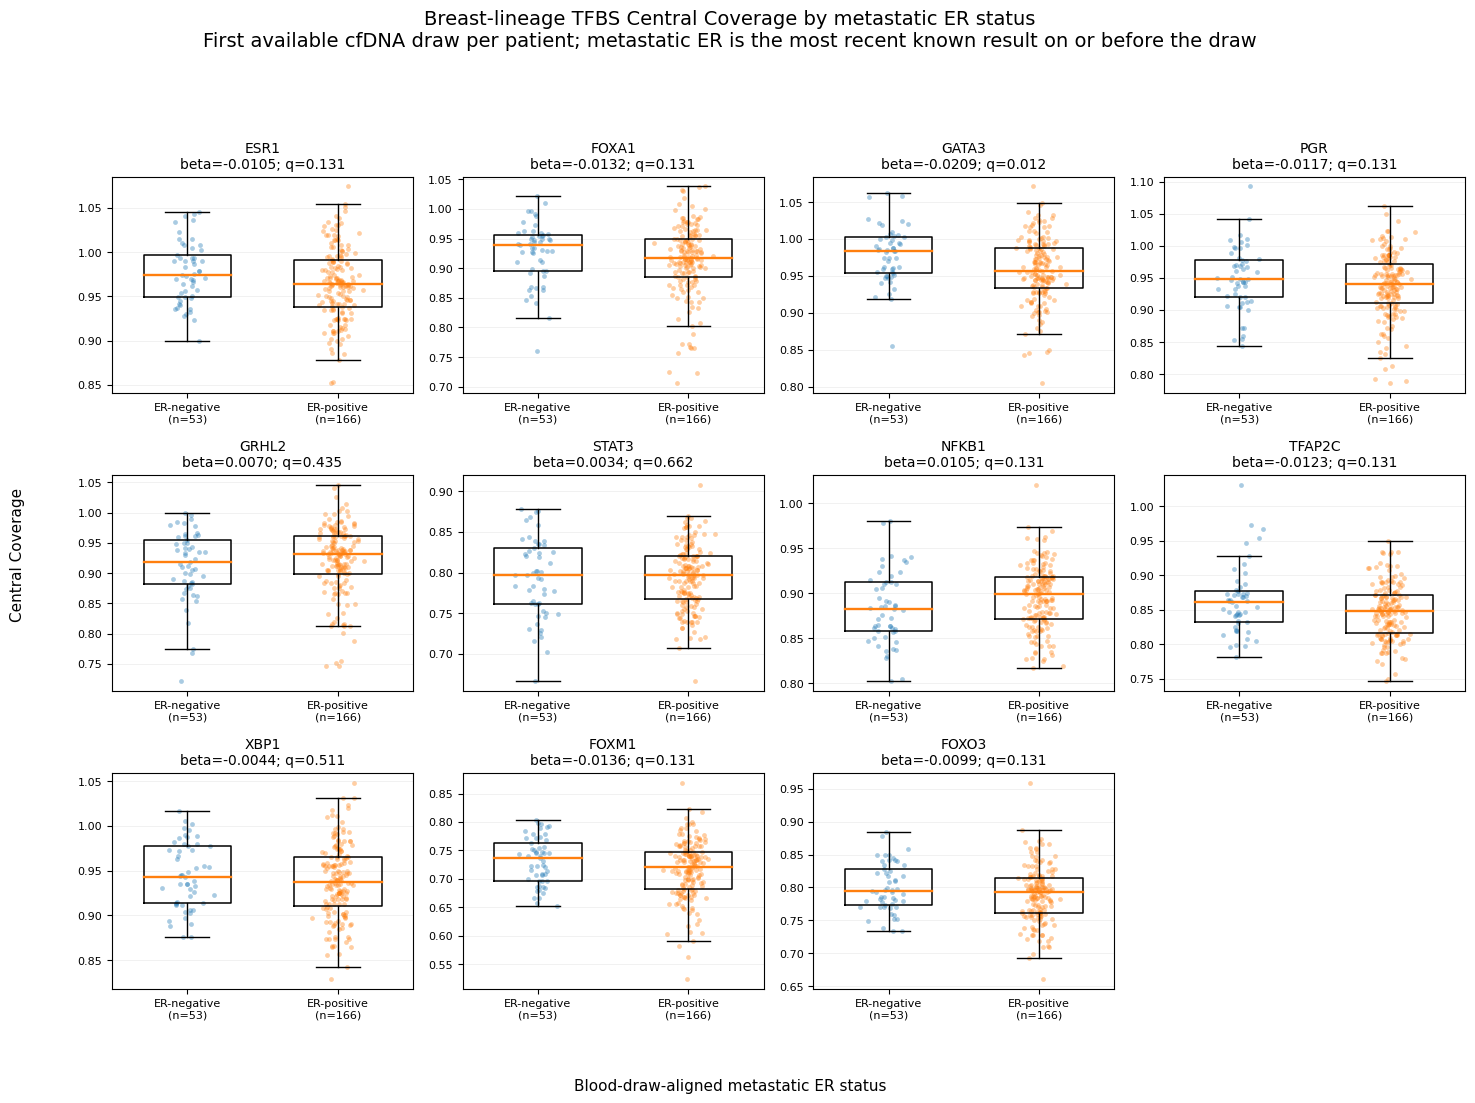

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Faceted_amplitude_ER_positive_vs_negative.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Faceted_amplitude_ER_positive_vs_negative.pdf


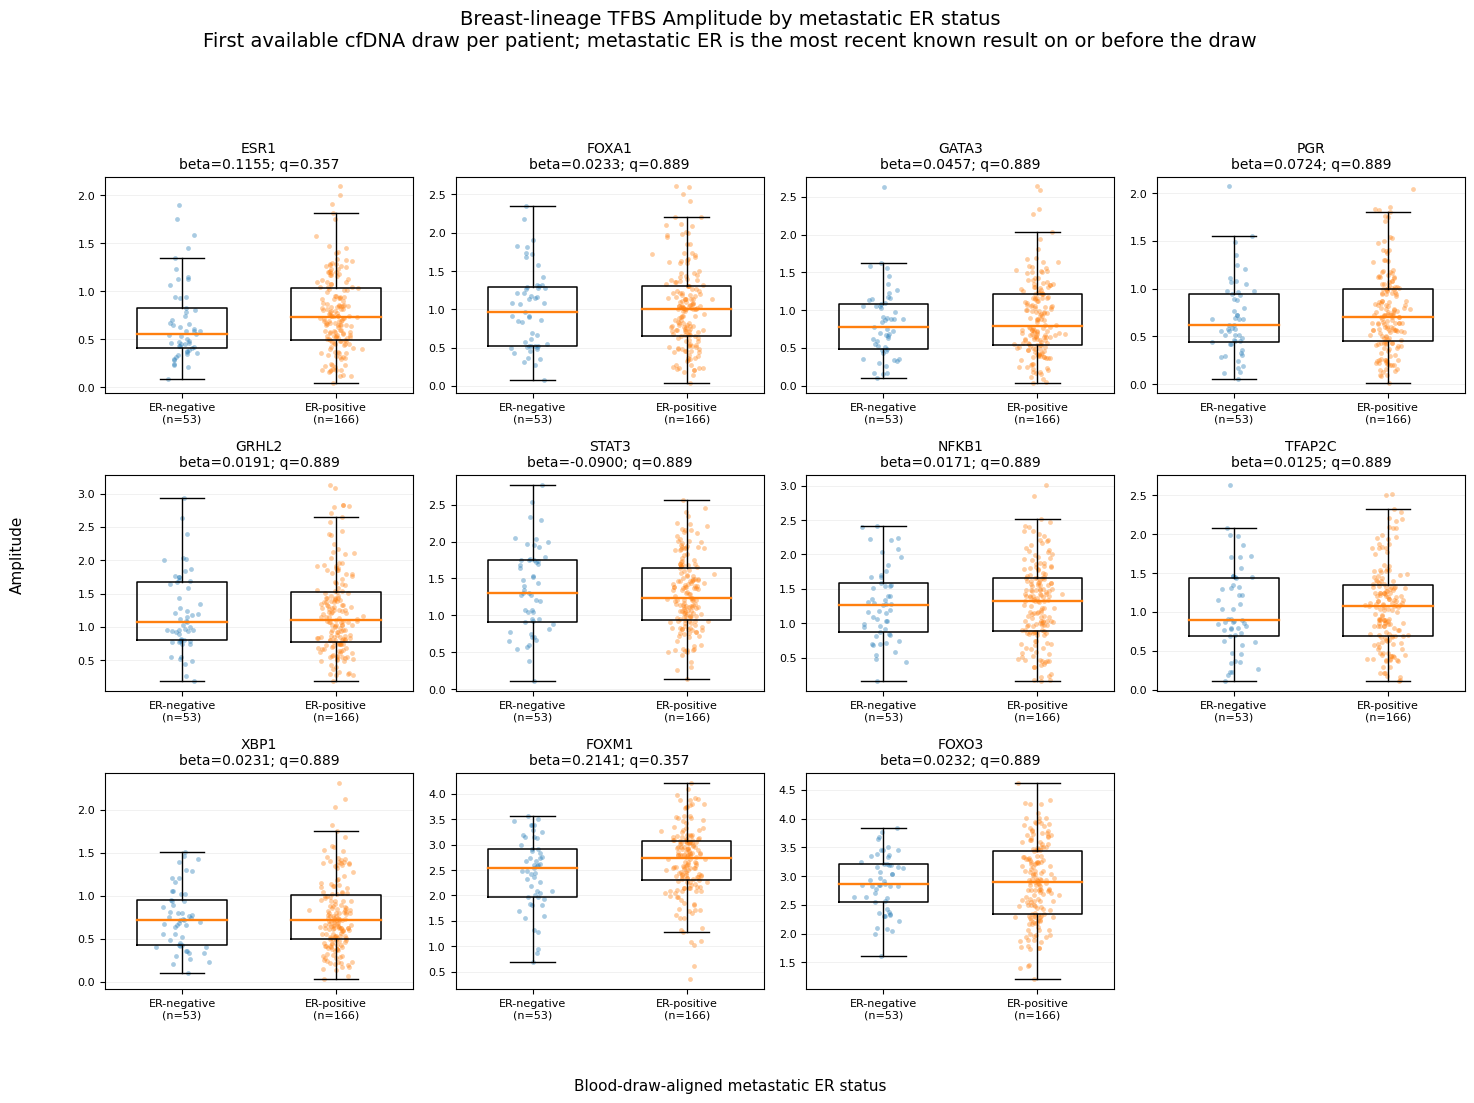

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Faceted_adjusted_forest_all_11_TFBS.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Faceted_adjusted_forest_all_11_TFBS.pdf


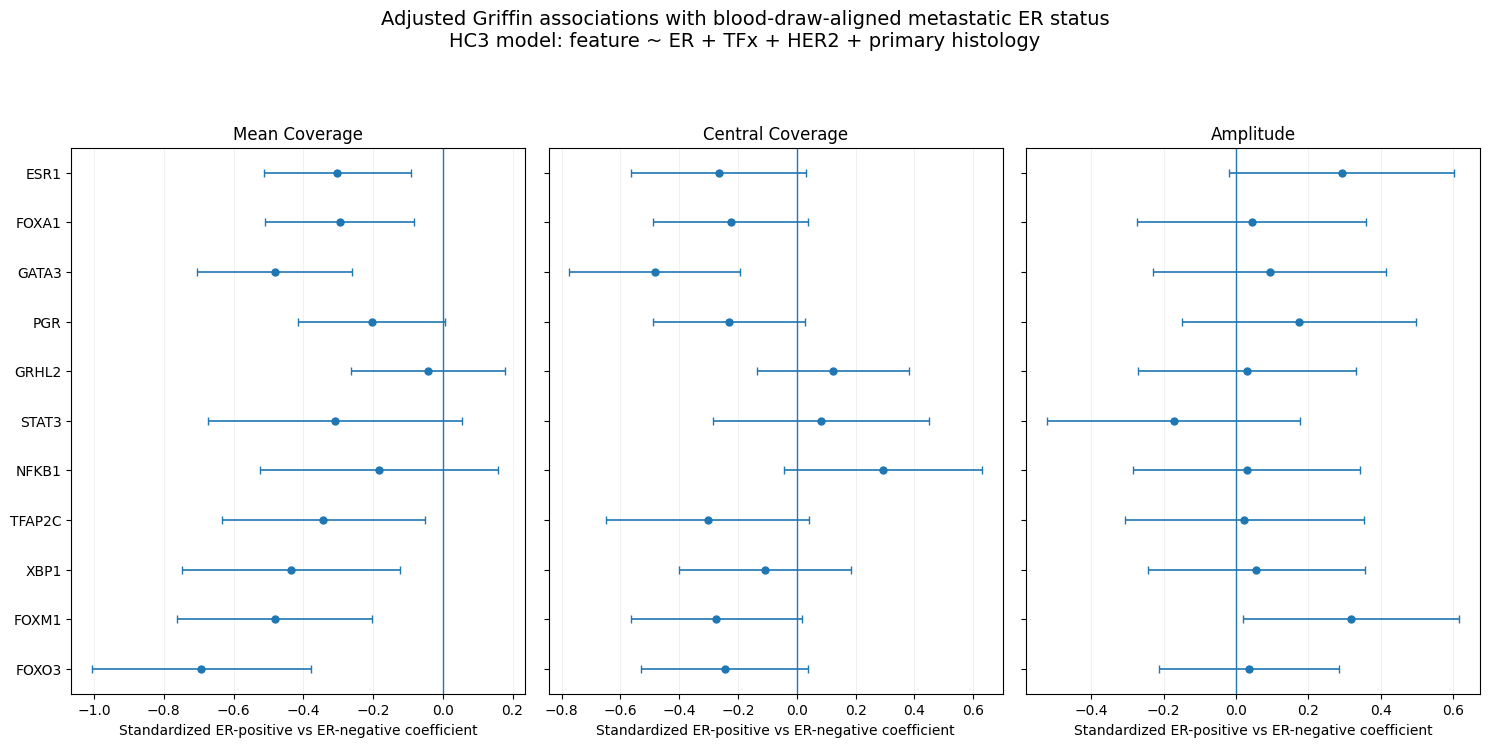

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Metastatic_ER_to_first_draw_lag.png
Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Metastatic_ER_to_first_draw_lag.pdf


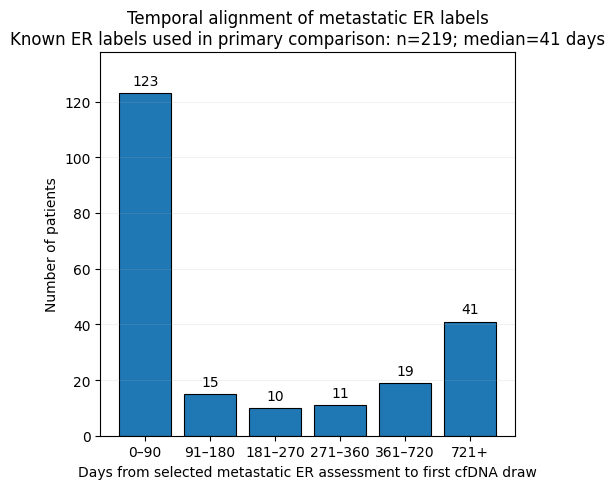

Saved formatted XLSX report: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/AURORA_Griffin_Met_ER_FirstDraw_results.xlsx
Saved detailed methods/results summary: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/Detailed_results_biological_question_and_steps.txt

Analysis completed successfully.
Output directory: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS
Generated files:
  - First_draw_blood_aligned_metastatic_ER_dataset.tsv
  - TFBS_ER_comparison_full_results.tsv
  - AURORA_Griffin_Met_ER_FirstDraw_results.xlsx
  - Detailed_results_biological_question_and_steps.txt
  - Faceted_mean_coverage_ER_positive_vs_negative.png
  - Faceted_mean_coverage_ER_positive_vs_negative.pdf
  - Faceted_central_coverage_ER_positive_vs_negative.png
  - Faceted_central_coverage_ER_positive_vs_negative.pdf
  - Faceted_amplit

In [16]:
"""
AURORA Griffin breast-lineage analysis:
Metastatic ER-positive versus ER-negative
==============================================================

BIOLOGICAL QUESTION
At the first available cfDNA blood draw, do Griffin nucleosome features at
breast-lineage TF-binding sites differ between metastatic ER-positive and
metastatic ER-negative breast-cancer cases?

PRIMARY DESIGN
1. Select the lowest available NB blood draw for each patient.
2. Read every Met_Diagnosis record and normalize ER to
   Positive, Negative, or Unknown.
3. For the selected draw, assign the most recent known ER result on or before
   that blood draw. If none exists, assign Unknown.
4. Match TFx and Griffin features from the same selected cfDNA draw.
5. Compare ER-positive versus ER-negative separately for mean coverage,
   central coverage, and amplitude across 11 breast-lineage TFBS collections.
6. Run Welch tests and HC3-robust adjusted regressions:
      feature ~ ER + TFx + HER2 + primary histology
7. Apply Benjamini-Hochberg FDR separately within each 11-TF feature family.
8. Save audit tables, complete results, faceted PNG/PDF plots, and an XLSX report.

REQUIRED PACKAGES
openpyxl, numpy, scipy, statsmodels, matplotlib
"""

from collections import defaultdict, Counter

import csv
import math
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st
import statsmodels.api as sm

from openpyxl import Workbook, load_workbook
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter, range_boundaries
from statsmodels.stats.multitest import multipletests


# =============================================================================
# INPUT AND OUTPUT FILES
# =============================================================================

CLINICAL_FILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

TFX_FILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Clinical_data/"
    "Metasheet_Analysis.with_Histology_Receptor_status."
    "Earliest_Met_Diagnosis.xlsx"
)

GRIFFIN_FILE = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/griffin_nucleosome_profiling/"
    "Griffin_30TF_GC_corrected_summary_by_module.xlsx"
)

OUTDIR = (
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS"
)


TF_ORDER = [
    "ESR1", "FOXA1", "GATA3", "PGR",
    "GRHL2", "STAT3", "NFKB1", "TFAP2C",
    "XBP1", "FOXM1", "FOXO3",
]

METRICS = [
    "mean_coverage", "central_coverage", "amplitude",
]

# =============================================================================
# HELPER FUNCTIONS
# =============================================================================

def norm_status(value):
    """
    Normalize receptor status to Positive, Negative, or None.

    None is later reported as Unknown.
    """
    if value is None:
        return None

    value = str(value).strip().lower()

    positive_values = {
        "positive",
        "pos",
        "+",
        "positive (+)",
        "positive/pos",
    }

    negative_values = {
        "negative",
        "neg",
        "-",
        "negative (-)",
        "negative/neg",
    }

    if value in positive_values:
        return "Positive"

    if value in negative_values:
        return "Negative"

    return None


def hist_cat(value):
    """Collapse primary histology into major categories."""
    if value is None:
        return None

    value = str(value).strip().lower()

    if not value:
        return None

    if "lobular" in value and "ductal" in value:
        return "Mixed"

    if "mixed" in value:
        return "Mixed"

    if "lobular" in value:
        return "Lobular"

    if "ductal" in value:
        return "Ductal"

    return "Other"


def safe_float(value):
    """Convert an Excel value to float, returning None when unavailable."""
    if value is None:
        return None

    if isinstance(value, str):
        value = value.strip()

        if value == "" or value.lower() in {
            "na",
            "n/a",
            "nan",
            "none",
            "unknown",
            ".",
        }:
            return None

        value = value.replace(",", "").replace("%", "")

    try:
        number = float(value)
    except (TypeError, ValueError):
        return None

    if not np.isfinite(number):
        return None

    return number


def normalize_id(value):
    """
    Normalize patient identifiers read from Excel.

    This prevents values such as 1101.0 from becoming '1101.0'
    when the expected patient identifier is '1101'.
    """
    if value is None:
        return None

    if isinstance(value, float) and value.is_integer():
        return str(int(value))

    return str(value).strip()


def clean_header(value):
    """Convert Excel header cells into stripped strings."""
    if value is None:
        return None

    return str(value).strip()


def sheet_values(path, sheet_name, cell_range=None):
    """
    Read values from an Excel worksheet using openpyxl.

    Parameters
    ----------
    path : str
        Full path to the XLSX file.
    sheet_name : str
        Exact worksheet name.
    cell_range : str or None
        Excel range such as 'A1:AE6729'. If None, the used worksheet
        dimensions are read.

    Returns
    -------
    list[list]
        Worksheet values as a list of rows.
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"Excel file not found:\n{path}")

    workbook = load_workbook(
        filename=path,
        read_only=True,
        data_only=True,
    )

    try:
        if sheet_name not in workbook.sheetnames:
            available = "\n  - ".join(workbook.sheetnames)

            raise ValueError(
                f"Worksheet '{sheet_name}' was not found in:\n"
                f"{path}\n\nAvailable worksheets:\n  - {available}"
            )

        worksheet = workbook[sheet_name]

        if cell_range is None:
            rows = worksheet.iter_rows(values_only=True)
        else:
            min_col, min_row, max_col, max_row = range_boundaries(cell_range)

            rows = worksheet.iter_rows(
                min_row=min_row,
                max_row=max_row,
                min_col=min_col,
                max_col=max_col,
                values_only=True,
            )

        return [list(row) for row in rows]

    finally:
        workbook.close()


def rows_to_dicts(values, required_first_column=True):
    """
    Convert a worksheet matrix into a list of dictionaries.

    The first row is treated as the header.
    """
    if not values:
        return []

    headers = [clean_header(x) for x in values[0]]

    if not any(headers):
        raise ValueError("No valid column headers were found.")

    records = []

    for row in values[1:]:
        if required_first_column and (not row or row[0] is None):
            continue

        record = {}

        for header, value in zip(headers, row):
            if header is not None:
                record[header] = value

        records.append(record)

    return records


def require_columns(records, required_columns, dataset_name):
    """Stop early when an expected column is absent."""
    if not records:
        raise ValueError(f"No records were read from {dataset_name}.")

    available = set(records[0].keys())
    missing = [x for x in required_columns if x not in available]

    if missing:
        raise KeyError(
            f"Missing required columns in {dataset_name}: {missing}\n"
            f"Available columns:\n{sorted(available)}"
        )


# =============================================================================
# CREATE OUTPUT DIRECTORY
# =============================================================================

os.makedirs(OUTDIR, exist_ok=True)


# =============================================================================
# READ EXCEL FILES
# =============================================================================

clinical_values = sheet_values(
    CLINICAL_FILE,
    "AUP_ClinicalData_20260609.NO.DA",
    "A1:AE6729",
)

meta_values = sheet_values(
    TFX_FILE,
    "Sheet1",
    "A1:S770",
)

griffin_values = sheet_values(
    GRIFFIN_FILE,
    "Breast_Lineage",
    "A1:AH771",
)


clinical = rows_to_dicts(clinical_values)
meta = rows_to_dicts(meta_values)


# =============================================================================
# CHECK REQUIRED COLUMNS
# =============================================================================

require_columns(
    clinical,
    [
        "patient_id",
        "Category",
        "Barcode",
        "Days_From_Primary_Diagnosis",
        "ER_Status",
        "PR_Status",
        "HER2_Status",
        "Histologic.type",
    ],
    "clinical workbook",
)

require_columns(
    meta,
    [
        "Collaborator_sample_id",
        "Patient_id",
        "Tumor_Fraction",
    ],
    "TFx metasheet",
)


# =============================================================================
# PREPARE TFx METASHEET
# =============================================================================

clean_meta = []

for row in meta:
    collaborator_sample_id = row.get("Collaborator_sample_id")
    patient_id = normalize_id(row.get("Patient_id"))

    if collaborator_sample_id is None or patient_id is None:
        continue

    sample = str(collaborator_sample_id).strip()
    sample = re.sub(r"^AUP-", "", sample, flags=re.IGNORECASE)

    nb_match = re.search(r"-NB(\d+)$", sample, flags=re.IGNORECASE)

    if not nb_match:
        print(
            "Warning: sample does not end with -NB<number> and was excluded:",
            sample,
        )
        continue

    row["sample"] = sample
    row["NB"] = int(nb_match.group(1))
    row["patient_id"] = patient_id

    clean_meta.append(row)

meta = clean_meta


# =============================================================================
# SELECT LOWEST NB DRAW PER PATIENT
# =============================================================================

by_patient = defaultdict(list)

for row in meta:
    by_patient[row["patient_id"]].append(row)


first_draw = {}

for patient_id, patient_rows in by_patient.items():
    first_draw[patient_id] = min(
        patient_rows,
        key=lambda x: x["NB"],
    )


print("Patients represented in TFx metasheet:", len(by_patient))
print("Patients with a selected first draw:", len(first_draw))


# =============================================================================
# PREPARE GRIFFIN DATA
# =============================================================================

# In the supplied workbook, the Griffin header was expected in Excel row 2.
# Therefore, Python index 1 is retained here.
GRIFFIN_HEADER_ROW_INDEX = 1

if len(griffin_values) <= GRIFFIN_HEADER_ROW_INDEX:
    raise ValueError(
        "The Griffin worksheet does not contain the expected header row."
    )

griffin_header = [
    clean_header(x)
    for x in griffin_values[GRIFFIN_HEADER_ROW_INDEX]
]

griffin = {}

for values_row in griffin_values[GRIFFIN_HEADER_ROW_INDEX + 1:]:
    if not values_row or values_row[0] is None:
        continue

    sample = str(values_row[0]).strip()
    sample = re.sub(r"^AUP-", "", sample, flags=re.IGNORECASE)

    row = {"sample": sample}

    for column_index in range(1, len(griffin_header)):
        header = griffin_header[column_index]

        if header is None:
            continue

        value = (
            values_row[column_index]
            if column_index < len(values_row)
            else None
        )

        numeric_value = safe_float(value)
        row[header] = numeric_value if numeric_value is not None else value

    griffin[sample] = row


print("Griffin samples loaded:", len(griffin))


# =============================================================================
# ORGANIZE CLINICAL RECORDS BY PATIENT
# =============================================================================

clinical_by_patient = defaultdict(list)

for row in clinical:
    patient_id = normalize_id(row.get("patient_id"))

    if patient_id is None:
        continue

    row["patient_id"] = patient_id
    clinical_by_patient[patient_id].append(row)


# =============================================================================
# BUILD FIRST-DRAW ANALYSIS TABLE
# =============================================================================

analysis = []

for patient_id, meta_row in first_draw.items():

    sample = meta_row["sample"]
    records = clinical_by_patient.get(patient_id, [])

    blood_records = []

    for record in records:
        if str(record.get("Category")).strip() != "Blood_Draw":
            continue

        barcode = record.get("Barcode")

        if barcode is None:
            continue

        normalized_barcode = re.sub(
            r"^AUP-",
            "",
            str(barcode).strip(),
            flags=re.IGNORECASE,
        )

        if normalized_barcode == sample:
            blood_records.append(record)

    if blood_records:
        blood_records = sorted(
            blood_records,
            key=lambda x: (
                safe_float(x.get("Days_From_Primary_Diagnosis"))
                is None,
                safe_float(x.get("Days_From_Primary_Diagnosis"))
                or math.inf,
            ),
        )

        blood_record = blood_records[0]
        draw_day = safe_float(
            blood_record.get("Days_From_Primary_Diagnosis")
        )
    else:
        draw_day = None

    metastatic_records = []

    for record in records:
        if str(record.get("Category")).strip() != "Met_Diagnosis":
            continue

        record_day = safe_float(
            record.get("Days_From_Primary_Diagnosis")
        )

        if record_day is None:
            continue

        metastatic_records.append((record_day, record))

    metastatic_records.sort(key=lambda x: x[0])

    known_er_records = [
        (record_day, record)
        for record_day, record in metastatic_records
        if norm_status(record.get("ER_Status")) is not None
    ]

    eligible_er_records = [
        (record_day, record)
        for record_day, record in known_er_records
        if draw_day is not None and record_day <= draw_day
    ]

    if eligible_er_records:
        er_source_day, chosen_record = max(
            eligible_er_records,
            key=lambda x: x[0],
        )
    else:
        er_source_day = None
        chosen_record = None

    primary_record = next(
        (
            record
            for record in records
            if str(record.get("Category")).strip() == "First_Primary"
        ),
        None,
    )

    tumor_fraction = safe_float(meta_row.get("Tumor_Fraction"))

    row = {
        "patient_id": patient_id,
        "sample": sample,
        "NB": meta_row["NB"],
        "draw_day": draw_day,

        "ER": (
            norm_status(chosen_record.get("ER_Status"))
            if chosen_record
            else None
        ),

        "ER_source_day": er_source_day,

        "ER_lag_days": (
            draw_day - er_source_day
            if draw_day is not None and er_source_day is not None
            else None
        ),

        "TFx_pct": (
            tumor_fraction * 100
            if tumor_fraction is not None
            else None
        ),

        "PR": (
            norm_status(chosen_record.get("PR_Status"))
            if chosen_record
            else None
        ),

        "HER2": (
            norm_status(chosen_record.get("HER2_Status"))
            if chosen_record
            else None
        ),

        "histology": (
            hist_cat(primary_record.get("Histologic.type"))
            if primary_record
            else None
        ),

        "met_records_total": len(metastatic_records),
        "met_records_known_ER": len(known_er_records),
        "griffin_matched": sample in griffin,
        "blood_draw_matched": draw_day is not None,
    }

    row.update(griffin.get(sample, {}))
    analysis.append(row)


# =============================================================================
# DISPLAY COHORT COUNTS
# =============================================================================

er_counts = Counter(
    row["ER"] if row["ER"] is not None else "Unknown"
    for row in analysis
)

print("\nMetastatic ER status at first draw:")
print("  ER-positive:", er_counts.get("Positive", 0))
print("  ER-negative:", er_counts.get("Negative", 0))
print("  ER-unknown:", er_counts.get("Unknown", 0))
print("  Total:", len(analysis))

print(
    "\nSamples with matched Griffin results:",
    sum(row["griffin_matched"] for row in analysis),
)

print(
    "Samples with matched blood-draw day:",
    sum(row["blood_draw_matched"] for row in analysis),
)


# =============================================================================
# STATISTICAL ANALYSIS
# =============================================================================

results = []

for tf_name in TF_ORDER:

    for metric in METRICS:

        feature = f"{tf_name}_{metric}"

        eligible_rows = []

        for row in analysis:
            feature_value = safe_float(row.get(feature))

            if row["ER"] not in {"Positive", "Negative"}:
                continue

            if feature_value is None:
                continue

            copied_row = dict(row)
            copied_row[feature] = feature_value
            eligible_rows.append(copied_row)

        positive_values = np.asarray(
            [
                row[feature]
                for row in eligible_rows
                if row["ER"] == "Positive"
            ],
            dtype=float,
        )

        negative_values = np.asarray(
            [
                row[feature]
                for row in eligible_rows
                if row["ER"] == "Negative"
            ],
            dtype=float,
        )

        result = {
            "TF": tf_name,
            "metric": metric,
            "feature": feature,
            "n_pos": len(positive_values),
            "n_neg": len(negative_values),
            "mean_pos": np.nan,
            "mean_neg": np.nan,
            "median_pos": np.nan,
            "median_neg": np.nan,
            "diff_mean": np.nan,
            "welch_p": np.nan,
            "adj_n": 0,
            "beta_ERpos": np.nan,
            "se": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p": np.nan,
            "std_beta": np.nan,
            "model_status": None,
        }

        if len(positive_values) > 0:
            result["mean_pos"] = np.mean(positive_values)
            result["median_pos"] = np.median(positive_values)

        if len(negative_values) > 0:
            result["mean_neg"] = np.mean(negative_values)
            result["median_neg"] = np.median(negative_values)

        if len(positive_values) > 0 and len(negative_values) > 0:
            result["diff_mean"] = (
                result["mean_pos"] - result["mean_neg"]
            )

        if len(positive_values) >= 2 and len(negative_values) >= 2:
            welch_test = st.ttest_ind(
                positive_values,
                negative_values,
                equal_var=False,
                nan_policy="omit",
            )

            result["welch_p"] = welch_test.pvalue

        complete_rows = [
            row
            for row in eligible_rows
            if row["TFx_pct"] is not None
            and row["HER2"] in {"Positive", "Negative"}
            and row["histology"] is not None
        ]

        result["adj_n"] = len(complete_rows)

        er_levels = set(row["ER"] for row in complete_rows)

        if len(complete_rows) < 8:
            result["model_status"] = "Too few complete observations"
            results.append(result)
            continue

        if er_levels != {"Positive", "Negative"}:
            result["model_status"] = "Only one ER group in complete cases"
            results.append(result)
            continue

        histology_counts = Counter(
            row["histology"]
            for row in complete_rows
        )

        # Use Ductal as the reference when available.
        if "Ductal" in histology_counts:
            histology_reference = "Ductal"
        else:
            histology_reference = histology_counts.most_common(1)[0][0]

        histology_levels = sorted(
            histology_counts,
            key=lambda x: (
                x != histology_reference,
                x,
            ),
        )

        design_matrix = []
        response = []

        for row in complete_rows:
            design_row = [
                1.0,
                1.0 if row["ER"] == "Positive" else 0.0,
                float(row["TFx_pct"]),
                1.0 if row["HER2"] == "Positive" else 0.0,
            ]

            for histology_level in histology_levels:
                if histology_level == histology_reference:
                    continue

                design_row.append(
                    1.0
                    if row["histology"] == histology_level
                    else 0.0
                )

            design_matrix.append(design_row)
            response.append(float(row[feature]))

        X = np.asarray(design_matrix, dtype=float)
        y = np.asarray(response, dtype=float)

        try:
            rank = np.linalg.matrix_rank(X)

            if rank < X.shape[1]:
                result["model_status"] = (
                    f"Rank-deficient design: rank {rank}/{X.shape[1]}"
                )
                results.append(result)
                continue

            fitted_model = sm.OLS(y, X).fit(cov_type="HC3")

            er_confidence_interval = fitted_model.conf_int()[1]

            result.update(
                {
                    "beta_ERpos": fitted_model.params[1],
                    "se": fitted_model.bse[1],
                    "ci_low": er_confidence_interval[0],
                    "ci_high": er_confidence_interval[1],
                    "p": fitted_model.pvalues[1],
                    "std_beta": (
                        fitted_model.params[1] / np.std(y, ddof=1)
                        if np.std(y, ddof=1) > 0
                        else np.nan
                    ),
                    "model_status": "OK",
                    "histology_reference": histology_reference,
                    "histology_levels": "; ".join(histology_levels),
                }
            )

        except Exception as error:
            result["model_status"] = (
                f"Model failed: {type(error).__name__}: {error}"
            )

        results.append(result)


# =============================================================================
# BENJAMINI-HOCHBERG FDR WITHIN EACH FEATURE FAMILY
# =============================================================================

for metric in METRICS:

    valid_indices = [
        index
        for index, row in enumerate(results)
        if row["metric"] == metric
        and np.isfinite(row.get("p", np.nan))
    ]

    if not valid_indices:
        continue

    p_values = [
        results[index]["p"]
        for index in valid_indices
    ]

    q_values = multipletests(
        p_values,
        method="fdr_bh",
    )[1]

    for index, q_value in zip(valid_indices, q_values):
        results[index]["q"] = q_value


for row in results:
    if "q" not in row:
        row["q"] = np.nan


# =============================================================================
# PRINT RESULTS SUMMARY
# =============================================================================

print("\nAdjusted model results:")
print(
    f"{'TF':<9} "
    f"{'Metric':<18} "
    f"{'N':>5} "
    f"{'Beta ER+':>12} "
    f"{'P':>11} "
    f"{'FDR Q':>11} "
    f"{'Status'}"
)

print("-" * 100)

for row in results:
    beta_text = (
        f"{row['beta_ERpos']:.5f}"
        if np.isfinite(row["beta_ERpos"])
        else "NA"
    )

    p_text = (
        f"{row['p']:.3g}"
        if np.isfinite(row["p"])
        else "NA"
    )

    q_text = (
        f"{row['q']:.3g}"
        if np.isfinite(row["q"])
        else "NA"
    )

    print(
        f"{row['TF']:<9} "
        f"{row['metric']:<18} "
        f"{row['adj_n']:>5} "
        f"{beta_text:>12} "
        f"{p_text:>11} "
        f"{q_text:>11} "
        f"{row['model_status']}"
    )


# =============================================================================
# CONTINUE WITH TSV, PLOTTING, AND XLSX EXPORT
# =============================================================================
# =============================================================================
# OUTPUT COLUMN DEFINITIONS
# =============================================================================

AUDIT_BASE_COLUMNS = [
    "patient_id",
    "sample",
    "NB",
    "draw_day",
    "ER",
    "ER_source_day",
    "ER_lag_days",
    "TFx_pct",
    "PR",
    "HER2",
    "histology",
    "met_records_total",
    "met_records_known_ER",
    "griffin_matched",
    "blood_draw_matched",
]

GRIFFIN_FEATURE_COLUMNS = [
    f"{tf_name}_{metric}"
    for tf_name in TF_ORDER
    for metric in METRICS
]

AUDIT_COLUMNS = AUDIT_BASE_COLUMNS + GRIFFIN_FEATURE_COLUMNS

RESULT_COLUMNS = [
    "TF",
    "metric",
    "feature",
    "n_pos",
    "n_neg",
    "mean_pos",
    "mean_neg",
    "median_pos",
    "median_neg",
    "diff_mean",
    "welch_p",
    "adj_n",
    "beta_ERpos",
    "se",
    "ci_low",
    "ci_high",
    "p",
    "q",
    "std_beta",
    "model_status",
    "histology_reference",
    "histology_levels",
]


# =============================================================================
# VALIDATE EXPECTED GRIFFIN FEATURES
# =============================================================================

missing_griffin_features = [
    feature
    for feature in GRIFFIN_FEATURE_COLUMNS
    if not any(feature in row for row in analysis)
]

if missing_griffin_features:
    raise KeyError(
        "The following expected Griffin columns were not found in the "
        "Breast_Lineage worksheet:\n  - "
        + "\n  - ".join(missing_griffin_features)
    )


# =============================================================================
# WRITE TSV FILES
# =============================================================================

AUDIT_TSV = os.path.join(
    OUTDIR,
    "First_draw_blood_aligned_metastatic_ER_dataset.tsv",
)

RESULTS_TSV = os.path.join(
    OUTDIR,
    "TFBS_ER_comparison_full_results.tsv",
)

with open(AUDIT_TSV, "w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(
        handle,
        fieldnames=AUDIT_COLUMNS,
        delimiter="\t",
        extrasaction="ignore",
    )
    writer.writeheader()

    for row in analysis:
        output_row = dict(row)
        output_row["ER"] = output_row.get("ER") or "Unknown"
        writer.writerow(output_row)

with open(RESULTS_TSV, "w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(
        handle,
        fieldnames=RESULT_COLUMNS,
        delimiter="\t",
        extrasaction="ignore",
    )
    writer.writeheader()
    writer.writerows(results)

print("\nSaved patient-level audit TSV:", AUDIT_TSV)
print("Saved full results TSV:", RESULTS_TSV)


# =============================================================================
# PLOT HELPERS
# =============================================================================

def finite_or_none(value):
    """Return a finite float or None."""
    number = safe_float(value)
    return number if number is not None and np.isfinite(number) else None


def q_label(value):
    """Compact q-value label for facet titles."""
    number = finite_or_none(value)

    if number is None:
        return "q=NA"

    if number < 0.001:
        return f"q={number:.1e}"

    return f"q={number:.3f}"


def beta_label(value):
    """Compact adjusted beta label for facet titles."""
    number = finite_or_none(value)
    return "beta=NA" if number is None else f"beta={number:.4f}"


def save_figure(fig, basename):
    """Save the same figure as 300-dpi PNG and vector PDF."""
    png_path = os.path.join(OUTDIR, f"{basename}.png")
    pdf_path = os.path.join(OUTDIR, f"{basename}.pdf")

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    print("Saved:", png_path)
    print("Saved:", pdf_path)


def metric_display(metric):
    """Human-readable feature-family name."""
    return metric.replace("_", " ").title()


# =============================================================================
# FACETED DISTRIBUTION PLOTS: 11 TFBS PANELS PER METRIC
# =============================================================================

for metric in METRICS:
    fig, axes = plt.subplots(
        nrows=3,
        ncols=4,
        figsize=(15, 11),
        constrained_layout=False,
    )

    axes = axes.ravel()

    metric_results = {
        row["TF"]: row
        for row in results
        if row["metric"] == metric
    }

    for panel_index, tf_name in enumerate(TF_ORDER):
        ax = axes[panel_index]
        feature = f"{tf_name}_{metric}"

        negative_values = np.asarray(
            [
                safe_float(row.get(feature))
                for row in analysis
                if row["ER"] == "Negative"
                and safe_float(row.get(feature)) is not None
            ],
            dtype=float,
        )

        positive_values = np.asarray(
            [
                safe_float(row.get(feature))
                for row in analysis
                if row["ER"] == "Positive"
                and safe_float(row.get(feature)) is not None
            ],
            dtype=float,
        )

        group_values = [negative_values, positive_values]
        group_labels = [
            f"ER-negative\n(n={len(negative_values)})",
            f"ER-positive\n(n={len(positive_values)})",
        ]

        ax.boxplot(
        group_values,
        labels=group_labels,
        showfliers=False,
        widths=0.58,
        medianprops={"linewidth": 1.7},
        boxprops={"linewidth": 1.1},
        whiskerprops={"linewidth": 1.0},
        capprops={"linewidth": 1.0},
        )

        # Deterministic jitter makes the figure reproducible.
        random_generator = np.random.default_rng(20260803 + panel_index)

        for x_position, values in enumerate(group_values, start=1):
            if len(values) == 0:
                continue

            jitter = random_generator.normal(
                loc=x_position,
                scale=0.055,
                size=len(values),
            )

            ax.scatter(
                jitter,
                values,
                s=12,
                alpha=0.38,
                linewidths=0,
            )

        result_row = metric_results[tf_name]

        ax.set_title(
            f"{tf_name}\n"
            f"{beta_label(result_row['beta_ERpos'])}; "
            f"{q_label(result_row['q'])}",
            fontsize=10,
        )
        ax.tick_params(axis="both", labelsize=8)
        ax.grid(axis="y", linewidth=0.4, alpha=0.3)

    # There are 12 axes in a 3 x 4 layout and only 11 TFBS collections.
    axes[-1].axis("off")

    fig.suptitle(
        f"Breast-lineage TFBS {metric_display(metric)} by metastatic ER status\n"
        "First available cfDNA draw per patient; metastatic ER is the most "
        "recent known result on or before the draw",
        fontsize=14,
        y=0.995,
    )

    fig.supxlabel("Blood-draw-aligned metastatic ER status", fontsize=11)
    fig.supylabel(metric_display(metric), fontsize=11)

    fig.tight_layout(rect=(0.035, 0.035, 1.0, 0.94))

    save_figure(
        fig,
        f"Faceted_{metric}_ER_positive_vs_negative",
    )
    plt.show()
    plt.close(fig)


# =============================================================================
# FACETED ADJUSTED FOREST PLOT: ALL 11 TFBS AND THREE FEATURE FAMILIES
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 7.5),
    sharey=True,
)

for ax, metric in zip(axes, METRICS):
    metric_rows = [
        next(
            row
            for row in results
            if row["TF"] == tf_name and row["metric"] == metric
        )
        for tf_name in TF_ORDER
    ]

    y_positions = np.arange(len(TF_ORDER))

    standardized_beta = []
    standardized_ci_low = []
    standardized_ci_high = []

    for row in metric_rows:
        beta = finite_or_none(row.get("beta_ERpos"))
        std_beta = finite_or_none(row.get("std_beta"))
        ci_low = finite_or_none(row.get("ci_low"))
        ci_high = finite_or_none(row.get("ci_high"))

        if (
            beta is None
            or std_beta is None
            or ci_low is None
            or ci_high is None
            or beta == 0
        ):
            standardized_beta.append(np.nan)
            standardized_ci_low.append(np.nan)
            standardized_ci_high.append(np.nan)
            continue

        outcome_sd = beta / std_beta
        standardized_beta.append(std_beta)
        standardized_ci_low.append(ci_low / outcome_sd)
        standardized_ci_high.append(ci_high / outcome_sd)

    standardized_beta = np.asarray(standardized_beta, dtype=float)
    standardized_ci_low = np.asarray(standardized_ci_low, dtype=float)
    standardized_ci_high = np.asarray(standardized_ci_high, dtype=float)

    valid = np.isfinite(standardized_beta)

    lower_error = (
        standardized_beta[valid] - standardized_ci_low[valid]
    )
    upper_error = (
        standardized_ci_high[valid] - standardized_beta[valid]
    )

    ax.errorbar(
        standardized_beta[valid],
        y_positions[valid],
        xerr=np.vstack([lower_error, upper_error]),
        fmt="o",
        capsize=3,
        markersize=5,
        linewidth=1.2,
    )

    ax.axvline(0, linewidth=1.0)
    ax.set_title(metric_display(metric), fontsize=12)
    ax.set_xlabel("Standardized ER-positive vs ER-negative coefficient")
    ax.set_yticks(y_positions)
    ax.set_yticklabels(TF_ORDER)
    ax.invert_yaxis()
    ax.grid(axis="x", linewidth=0.4, alpha=0.3)

fig.suptitle(
    "Adjusted Griffin associations with blood-draw-aligned metastatic ER status\n"
    "HC3 model: feature ~ ER + TFx + HER2 + primary histology",
    fontsize=14,
    y=0.99,
)

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.93))
save_figure(fig, "Faceted_adjusted_forest_all_11_TFBS")
plt.show()
plt.close(fig)


# =============================================================================
# METASTATIC ER ASSESSMENT-TO-BLOOD-DRAW LAG PLOT
# =============================================================================

lag_values = np.asarray(
    [
        row["ER_lag_days"]
        for row in analysis
        if row["ER"] in {"Positive", "Negative"}
        and finite_or_none(row.get("ER_lag_days")) is not None
    ],
    dtype=float,
)
# =============================================================================
# METASTATIC ER ASSESSMENT-TO-BLOOD-DRAW LAG PLOT
# Categories: 0–90, 91–180, 181–270, 271–360, 361–720, 721+ days
# =============================================================================

lag_labels = [
    "0–90",
    "91–180",
    "181–270",
    "271–360",
    "361–720",
    "721+",
]

# Count patients in each non-overlapping category.
# The underlying lag values may be continuous, so:
# 0–90 means 0 <= lag <= 90
# 91–180 means 90 < lag <= 180, and so forth.
lag_counts = [
    int(np.sum((lag_values >= 0) & (lag_values <= 90))),
    int(np.sum((lag_values > 90) & (lag_values <= 180))),
    int(np.sum((lag_values > 180) & (lag_values <= 270))),
    int(np.sum((lag_values > 270) & (lag_values <= 360))),
    int(np.sum((lag_values > 360) & (lag_values <= 720))),
    int(np.sum(lag_values > 720)),
]

fig, ax = plt.subplots(figsize=(5, 5))

x_positions = np.arange(len(lag_labels))

bars = ax.bar(
    x_positions,
    lag_counts,
    width=0.8,
    edgecolor="black",
    linewidth=0.8,
)

# Each label is positioned at the center of its corresponding bar.
ax.set_xticks(x_positions)
ax.set_xticklabels(lag_labels)

# Add the number of patients above each bar.
maximum_count = max(lag_counts) if lag_counts else 0
label_offset = max(maximum_count * 0.015, 0.5)

for bar, count in zip(bars, lag_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + label_offset,
        str(count),
        ha="center",
        va="bottom",
        fontsize=10,
    )

median_lag = (
    float(np.median(lag_values))
    if len(lag_values) > 0
    else np.nan
)

ax.set_xlabel(
    "Days from selected metastatic ER assessment to first cfDNA draw"
)
ax.set_ylabel("Number of patients")

ax.set_title(
    "Temporal alignment of metastatic ER labels\n"
    f"Known ER labels used in primary comparison: n={len(lag_values)}; "
    f"median={median_lag:.0f} days"
)

ax.grid(
    axis="y",
    linewidth=0.4,
    alpha=0.3,
)

# Keep count labels inside the plotting area.
ax.set_ylim(
    0,
    maximum_count + max(maximum_count * 0.12, 3),
)

fig.tight_layout()

save_figure(
    fig,
    "Metastatic_ER_to_first_draw_lag",
)
plt.show()
plt.close(fig)

# =============================================================================
# CREATE FORMATTED XLSX REPORT WITH OPENPYXL
# =============================================================================

XLSX_FILE = os.path.join(
    OUTDIR,
    "AURORA_Griffin_Met_ER_FirstDraw_results.xlsx",
)

workbook = Workbook()

# Reusable workbook styles.
header_fill = PatternFill("solid", fgColor="1F4E78")
section_fill = PatternFill("solid", fgColor="D9EAF7")
significant_fill = PatternFill("solid", fgColor="E2F0D9")
warning_fill = PatternFill("solid", fgColor="FFF2CC")
white_font = Font(color="FFFFFF", bold=True)
bold_font = Font(bold=True)
thin_gray = Side(style="thin", color="D9E1F2")
thin_border = Border(
    left=thin_gray,
    right=thin_gray,
    top=thin_gray,
    bottom=thin_gray,
)


def style_header(worksheet, row_number=1):
    """Apply the standard header style to an entire populated row."""
    for cell in worksheet[row_number]:
        cell.fill = header_fill
        cell.font = white_font
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )
        cell.border = thin_border


def set_reasonable_widths(worksheet, minimum=10, maximum=35):
    """Set bounded widths based on populated cell contents."""
    for column_cells in worksheet.columns:
        column_letter = get_column_letter(column_cells[0].column)
        max_length = 0

        for cell in column_cells:
            if cell.value is None:
                continue

            value_length = max(
                len(part)
                for part in str(cell.value).split("\n")
            )
            max_length = max(max_length, value_length)

        worksheet.column_dimensions[column_letter].width = min(
            max(max_length + 2, minimum),
            maximum,
        )


# README sheet.
readme_sheet = workbook.active
readme_sheet.title = "README"

readme_rows = [
    ["AURORA Griffin breast-lineage metastatic ER analysis", None],
    [
        "Biological question",
        "At the first available cfDNA blood draw, do Griffin nucleosome "
        "features at breast-lineage TF-binding sites differ between "
        "metastatic ER-positive and metastatic ER-negative breast-cancer "
        "cases?",
    ],
    ["Receptor source", "Met_Diagnosis"],
    [
        "Primary ER assignment",
        "Most recent known Positive or Negative metastatic ER result on or "
        "before the selected first cfDNA draw.",
    ],
    ["First-draw rule", "Lowest available NB number per patient."],
    [
        "Unknown handling",
        "No known metastatic ER result on or before the selected draw was "
        "classified as Unknown. Unknown cases were retained in the audit "
        "table but excluded from ER-positive versus ER-negative testing.",
    ],
    [
        "Feature families",
        "Mean coverage, central coverage, and amplitude were analyzed "
        "separately for 11 breast-lineage TFBS collections.",
    ],
    ["TFBS collections", ", ".join(TF_ORDER)],
    ["Unadjusted analysis", "Welch two-sample t-test."],
    [
        "Adjusted model",
        "HC3-robust linear regression: Griffin feature ~ metastatic ER + "
        "TFx + HER2 + primary histology.",
    ],
    [
        "Multiple testing",
        "Benjamini-Hochberg FDR separately within each feature family of "
        "11 TF tests.",
    ],
    [
        "Cohort counts",
        f"ER-positive={er_counts.get('Positive', 0)}; "
        f"ER-negative={er_counts.get('Negative', 0)}; "
        f"Unknown={er_counts.get('Unknown', 0)}; total={len(analysis)}.",
    ],
    [
        "Interpretation caution",
        "The results describe adjusted associations in nucleosome-profile "
        "summary features. They do not by themselves prove direct TF "
        "occupancy, receptor conversion, causality, or predictive performance.",
    ],
]

for row in readme_rows:
    readme_sheet.append(row)

readme_sheet.merge_cells("A1:B1")
readme_sheet["A1"].fill = header_fill
readme_sheet["A1"].font = Font(color="FFFFFF", bold=True, size=14)
readme_sheet["A1"].alignment = Alignment(horizontal="center")

for row_number in range(2, len(readme_rows) + 1):
    readme_sheet.cell(row=row_number, column=1).fill = section_fill
    readme_sheet.cell(row=row_number, column=1).font = bold_font

    for column_number in (1, 2):
        cell = readme_sheet.cell(row=row_number, column=column_number)
        cell.alignment = Alignment(vertical="top", wrap_text=True)
        cell.border = thin_border

readme_sheet.column_dimensions["A"].width = 26
readme_sheet.column_dimensions["B"].width = 90
readme_sheet.freeze_panes = "A2"

# Cohort counts sheet.
counts_sheet = workbook.create_sheet("Cohort Counts")
counts_sheet.append(["Group", "Patients", "Percent of 262"])
counts_sheet.append([
    "ER-positive",
    er_counts.get("Positive", 0),
    er_counts.get("Positive", 0) / len(analysis) if analysis else np.nan,
])
counts_sheet.append([
    "ER-negative",
    er_counts.get("Negative", 0),
    er_counts.get("Negative", 0) / len(analysis) if analysis else np.nan,
])
counts_sheet.append([
    "Unknown",
    er_counts.get("Unknown", 0),
    er_counts.get("Unknown", 0) / len(analysis) if analysis else np.nan,
])
counts_sheet.append(["Total", len(analysis), 1.0])
counts_sheet.append([
    "Known ER used for unadjusted testing",
    er_counts.get("Positive", 0) + er_counts.get("Negative", 0),
    (
        er_counts.get("Positive", 0) + er_counts.get("Negative", 0)
    ) / len(analysis) if analysis else np.nan,
])

adjusted_ns = [
    row["adj_n"]
    for row in results
    if row.get("model_status") == "OK"
]

counts_sheet.append([
    "Adjusted complete-case N",
    min(adjusted_ns) if adjusted_ns else 0,
    (min(adjusted_ns) / len(analysis)) if analysis and adjusted_ns else 0,
])

style_header(counts_sheet)
counts_sheet.freeze_panes = "A2"

for cell in counts_sheet["C"][1:]:
    cell.number_format = "0.0%"

for row in counts_sheet.iter_rows():
    for cell in row:
        cell.border = thin_border

set_reasonable_widths(counts_sheet, maximum=38)

# TFBS results sheet.
results_sheet = workbook.create_sheet("TFBS Results")
results_sheet.append(RESULT_COLUMNS)

for result_row in results:
    results_sheet.append([
        result_row.get(column)
        for column in RESULT_COLUMNS
    ])

style_header(results_sheet)
results_sheet.freeze_panes = "A2"
results_sheet.auto_filter.ref = results_sheet.dimensions

numeric_headers = {
    "mean_pos",
    "mean_neg",
    "median_pos",
    "median_neg",
    "diff_mean",
    "welch_p",
    "beta_ERpos",
    "se",
    "ci_low",
    "ci_high",
    "p",
    "q",
    "std_beta",
}

header_to_column = {
    cell.value: cell.column
    for cell in results_sheet[1]
}

for header in numeric_headers:
    column_number = header_to_column[header]

    for row_number in range(2, results_sheet.max_row + 1):
        results_sheet.cell(
            row=row_number,
            column=column_number,
        ).number_format = "0.000000"

q_column = header_to_column["q"]

for row_number in range(2, results_sheet.max_row + 1):
    q_value = finite_or_none(
        results_sheet.cell(row=row_number, column=q_column).value
    )

    if q_value is not None and q_value < 0.05:
        for cell in results_sheet[row_number]:
            cell.fill = significant_fill

    for cell in results_sheet[row_number]:
        cell.border = thin_border

set_reasonable_widths(results_sheet, maximum=28)

# Patient-level audit sheet.
audit_sheet = workbook.create_sheet("Patient Audit")
audit_sheet.append(AUDIT_COLUMNS)

for analysis_row in analysis:
    audit_sheet.append([
        (
            analysis_row.get(column)
            if column != "ER"
            else analysis_row.get("ER") or "Unknown"
        )
        for column in AUDIT_COLUMNS
    ])

style_header(audit_sheet)
audit_sheet.freeze_panes = "A2"
audit_sheet.auto_filter.ref = audit_sheet.dimensions

for row in audit_sheet.iter_rows():
    for cell in row:
        cell.border = thin_border

set_reasonable_widths(audit_sheet, maximum=24)

# Flag unknown ER rows for easy audit.
audit_er_column = AUDIT_COLUMNS.index("ER") + 1

for row_number in range(2, audit_sheet.max_row + 1):
    if audit_sheet.cell(row=row_number, column=audit_er_column).value == "Unknown":
        for cell in audit_sheet[row_number]:
            cell.fill = warning_fill

# Significant-results summary sheet.
significant_sheet = workbook.create_sheet("FDR Significant")
significant_sheet.append(RESULT_COLUMNS)

significant_results = sorted(
    [
        row
        for row in results
        if finite_or_none(row.get("q")) is not None
        and row["q"] < 0.05
    ],
    key=lambda row: (METRICS.index(row["metric"]), row["q"]),
)

for result_row in significant_results:
    significant_sheet.append([
        result_row.get(column)
        for column in RESULT_COLUMNS
    ])

style_header(significant_sheet)
significant_sheet.freeze_panes = "A2"
significant_sheet.auto_filter.ref = significant_sheet.dimensions

for row in significant_sheet.iter_rows():
    for cell in row:
        cell.border = thin_border

set_reasonable_widths(significant_sheet, maximum=28)

workbook.save(XLSX_FILE)
print("Saved formatted XLSX report:", XLSX_FILE)


# =============================================================================
# WRITE PLAIN-TEXT METHODS AND RESULTS SUMMARY
# =============================================================================

SUMMARY_FILE = os.path.join(
    OUTDIR,
    "Detailed_results_biological_question_and_steps.txt",
)

summary_lines = [
    "AURORA Griffin breast-lineage analysis: metastatic ER+ versus ER-",
    "================================================================",
    "",
    "BIOLOGICAL QUESTION",
    "At the first available cfDNA blood draw, do Griffin nucleosome "
    "features at breast-lineage TF-binding sites differ between metastatic "
    "ER-positive and metastatic ER-negative breast-cancer cases?",
    "",
    "PRIMARY STEPS",
    "1. Selected the lowest available NB blood draw for each patient.",
    "2. Read all Met_Diagnosis records and normalized ER to Positive, "
    "Negative, or Unknown.",
    "3. Assigned the most recent known metastatic ER result occurring on "
    "or before the selected blood draw.",
    "4. Assigned Unknown when no known metastatic ER result was available "
    "on or before the draw.",
    "5. Matched TFx and Griffin summary features from the same selected draw.",
    "6. Compared ER-positive versus ER-negative separately for mean "
    "coverage, central coverage, and amplitude across 11 TFBS collections.",
    "7. Used Welch tests and HC3-robust adjusted regression:",
    "   feature ~ ER + TFx + HER2 + primary histology",
    "8. Applied BH FDR separately within each 11-TF feature family.",
    "",
    "COHORT COUNTS",
    f"Total patients: {len(analysis)}",
    f"ER-positive: {er_counts.get('Positive', 0)}",
    f"ER-negative: {er_counts.get('Negative', 0)}",
    f"Unknown: {er_counts.get('Unknown', 0)}",
    f"Known ER included in unadjusted testing: "
    f"{er_counts.get('Positive', 0) + er_counts.get('Negative', 0)}",
    f"Adjusted complete-case N: {min(adjusted_ns) if adjusted_ns else 0}",
    "",
    "FDR-SIGNIFICANT ADJUSTED RESULTS",
]

for metric in METRICS:
    summary_lines.append("")
    summary_lines.append(metric_display(metric).upper())

    metric_significant = [
        row
        for row in significant_results
        if row["metric"] == metric
    ]

    if not metric_significant:
        summary_lines.append("No TFBS passed q < 0.05.")
        continue

    for row in metric_significant:
        summary_lines.append(
            f"{row['TF']}: beta={row['beta_ERpos']:.6f}; "
            f"standardized beta={row['std_beta']:.3f}; "
            f"95% CI={row['ci_low']:.6f} to {row['ci_high']:.6f}; "
            f"p={row['p']:.4g}; q={row['q']:.4g}; "
            f"adjusted N={row['adj_n']}."
        )

summary_lines.extend(
    [
        "",
        "INTERPRETATION",
        "A negative ER coefficient indicates a lower Griffin feature value "
        "in ER-positive than ER-negative metastatic cases after adjustment.",
        "The analysis tests association at the first cfDNA draw. It does not "
        "by itself establish direct TF occupancy, receptor conversion, "
        "causality, or out-of-sample predictive performance.",
        "",
        "OUTPUT FILES",
        os.path.basename(AUDIT_TSV),
        os.path.basename(RESULTS_TSV),
        os.path.basename(XLSX_FILE),
        "Faceted_mean_coverage_ER_positive_vs_negative.png/.pdf",
        "Faceted_central_coverage_ER_positive_vs_negative.png/.pdf",
        "Faceted_amplitude_ER_positive_vs_negative.png/.pdf",
        "Faceted_adjusted_forest_all_11_TFBS.png/.pdf",
        "Metastatic_ER_to_first_draw_lag.png/.pdf",
    ]
)

with open(SUMMARY_FILE, "w", encoding="utf-8") as handle:
    handle.write("\n".join(summary_lines) + "\n")

print("Saved detailed methods/results summary:", SUMMARY_FILE)


# =============================================================================
# FINAL REPRODUCIBILITY CHECKS
# =============================================================================

expected_output_files = [
    AUDIT_TSV,
    RESULTS_TSV,
    XLSX_FILE,
    SUMMARY_FILE,
]

for metric in METRICS:
    expected_output_files.extend(
        [
            os.path.join(
                OUTDIR,
                f"Faceted_{metric}_ER_positive_vs_negative.png",
            ),
            os.path.join(
                OUTDIR,
                f"Faceted_{metric}_ER_positive_vs_negative.pdf",
            ),
        ]
    )

expected_output_files.extend(
    [
        os.path.join(OUTDIR, "Faceted_adjusted_forest_all_11_TFBS.png"),
        os.path.join(OUTDIR, "Faceted_adjusted_forest_all_11_TFBS.pdf"),
        os.path.join(OUTDIR, "Metastatic_ER_to_first_draw_lag.png"),
        os.path.join(OUTDIR, "Metastatic_ER_to_first_draw_lag.pdf"),
    ]
)

missing_output_files = [
    path
    for path in expected_output_files
    if not os.path.exists(path)
]

if missing_output_files:
    raise RuntimeError(
        "Analysis completed, but the following output files are missing:\n  - "
        + "\n  - ".join(missing_output_files)
    )

print("\nAnalysis completed successfully.")
print("Output directory:", OUTDIR)
print("Generated files:")

for path in expected_output_files:
    print("  -", os.path.basename(path))

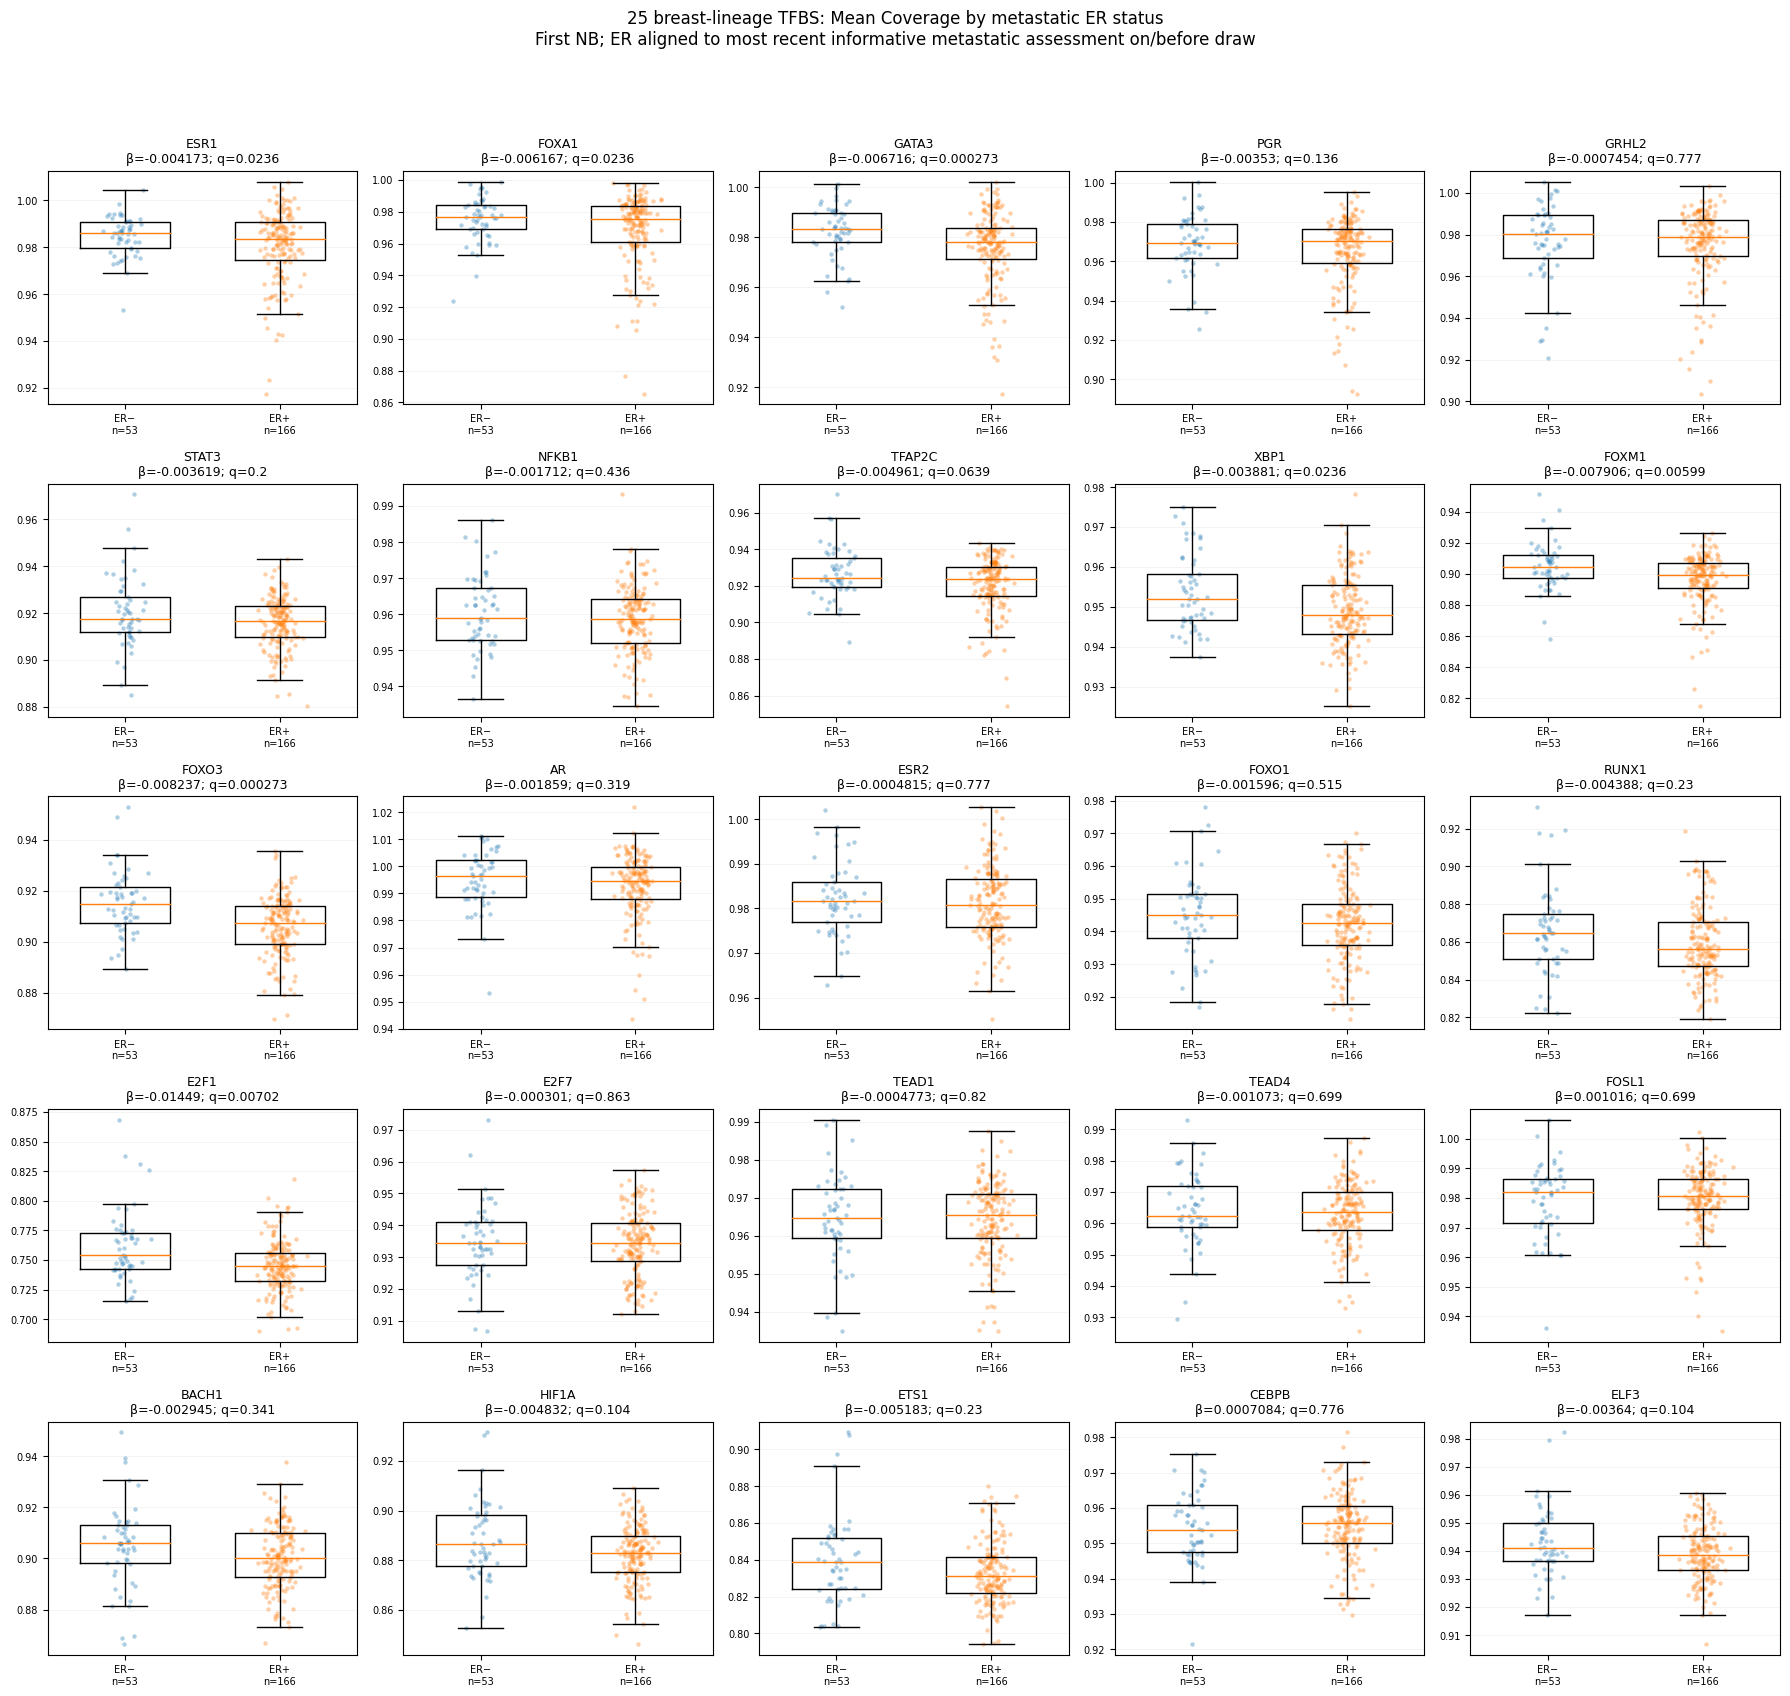

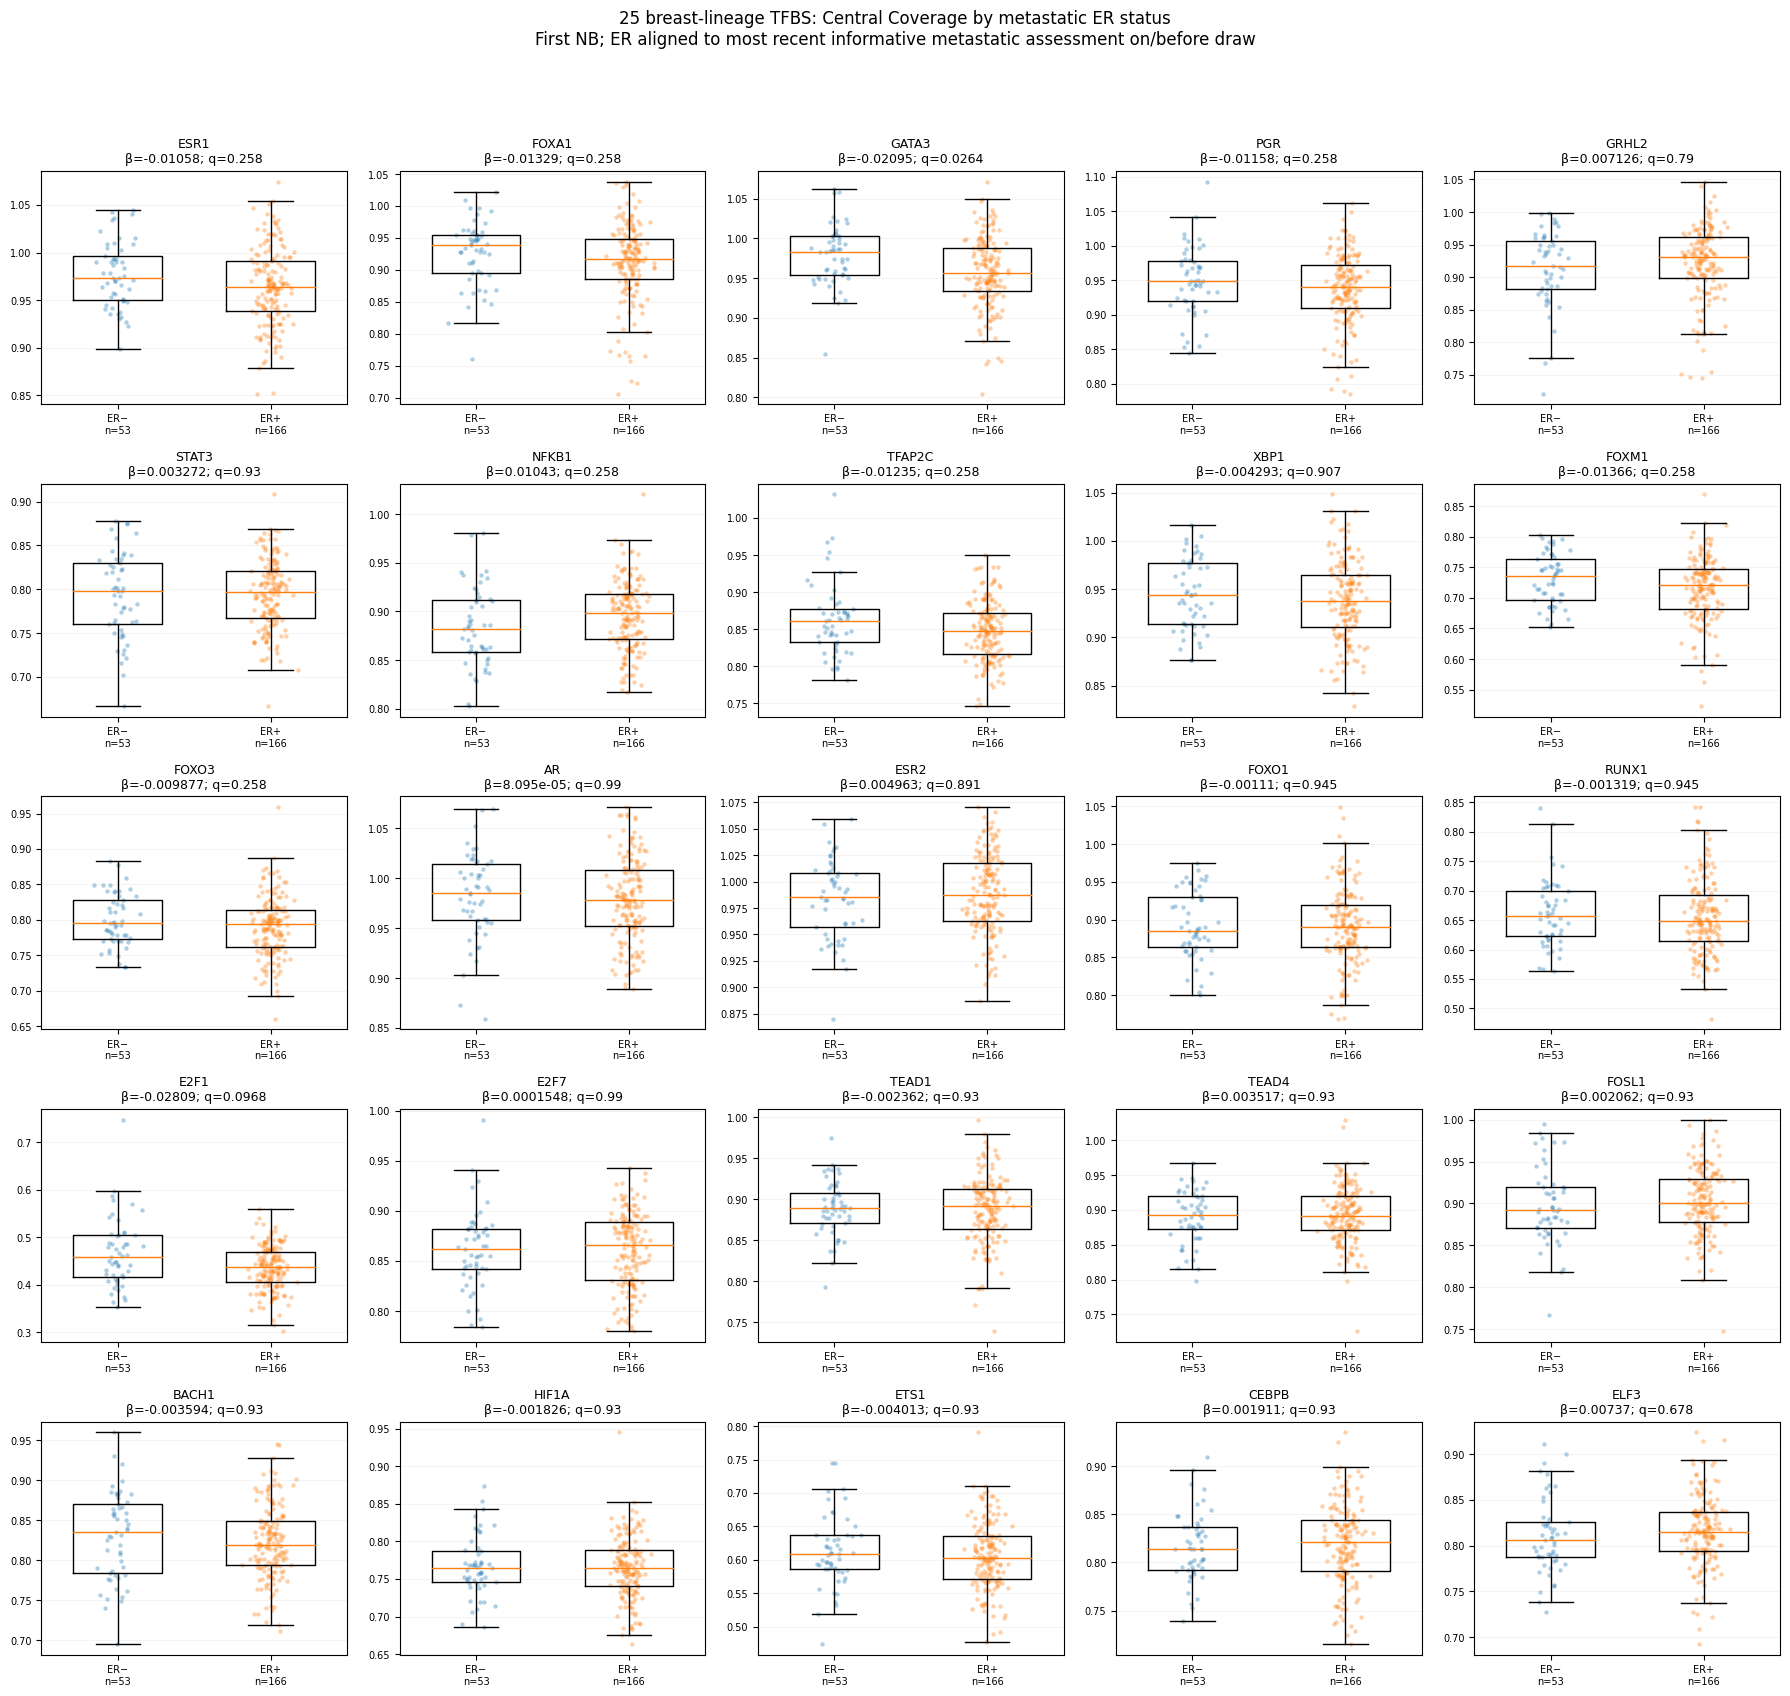

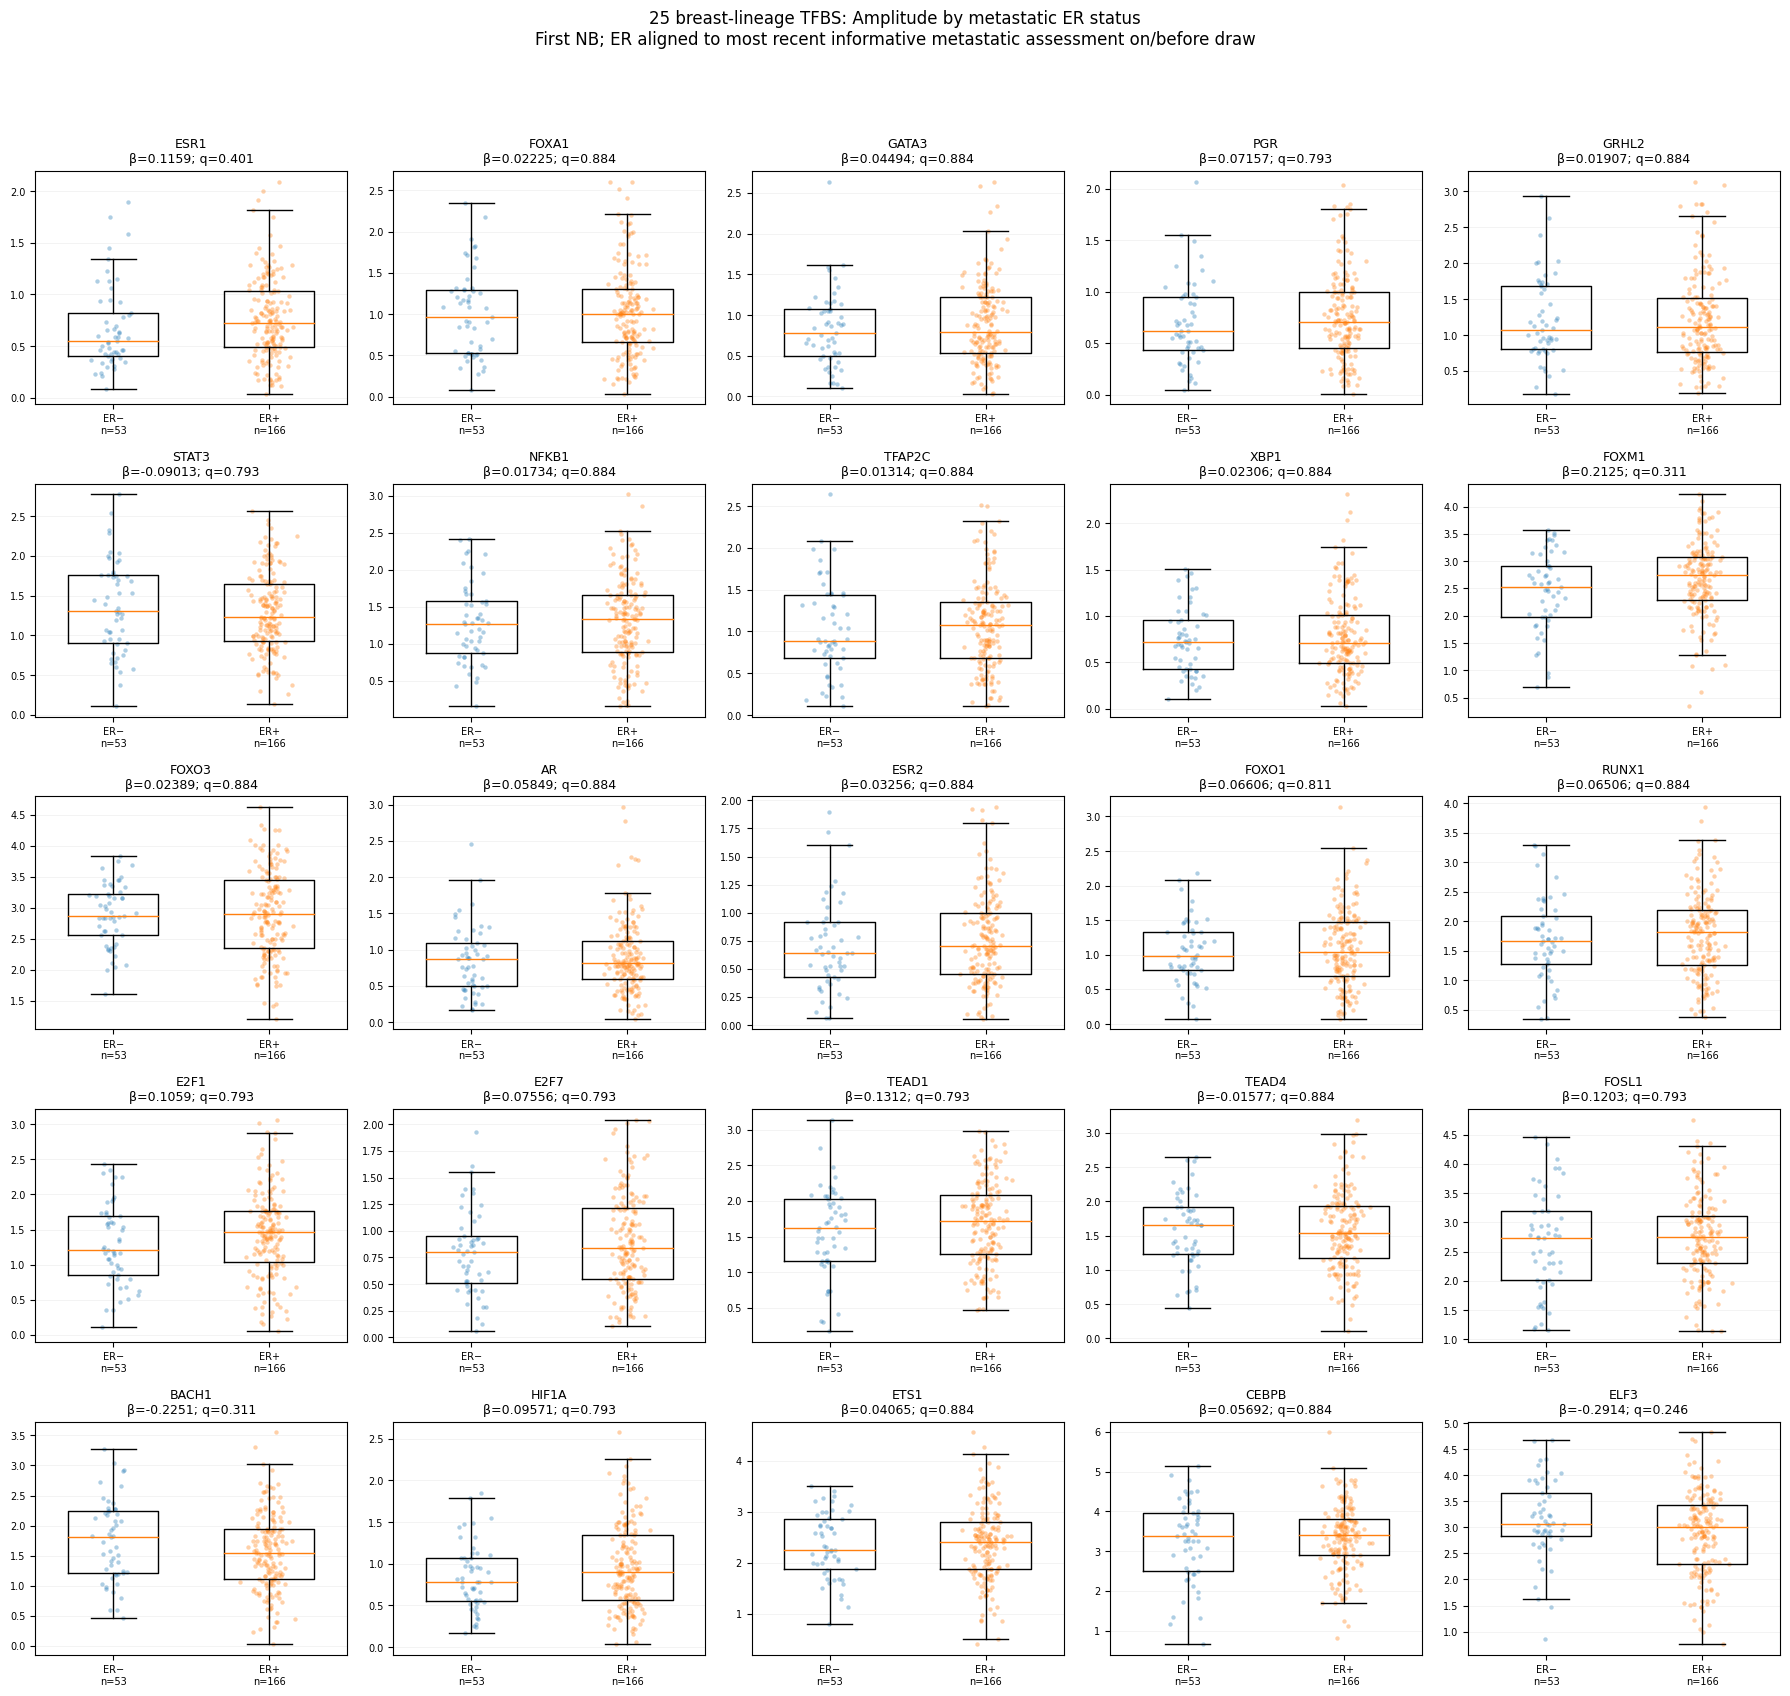

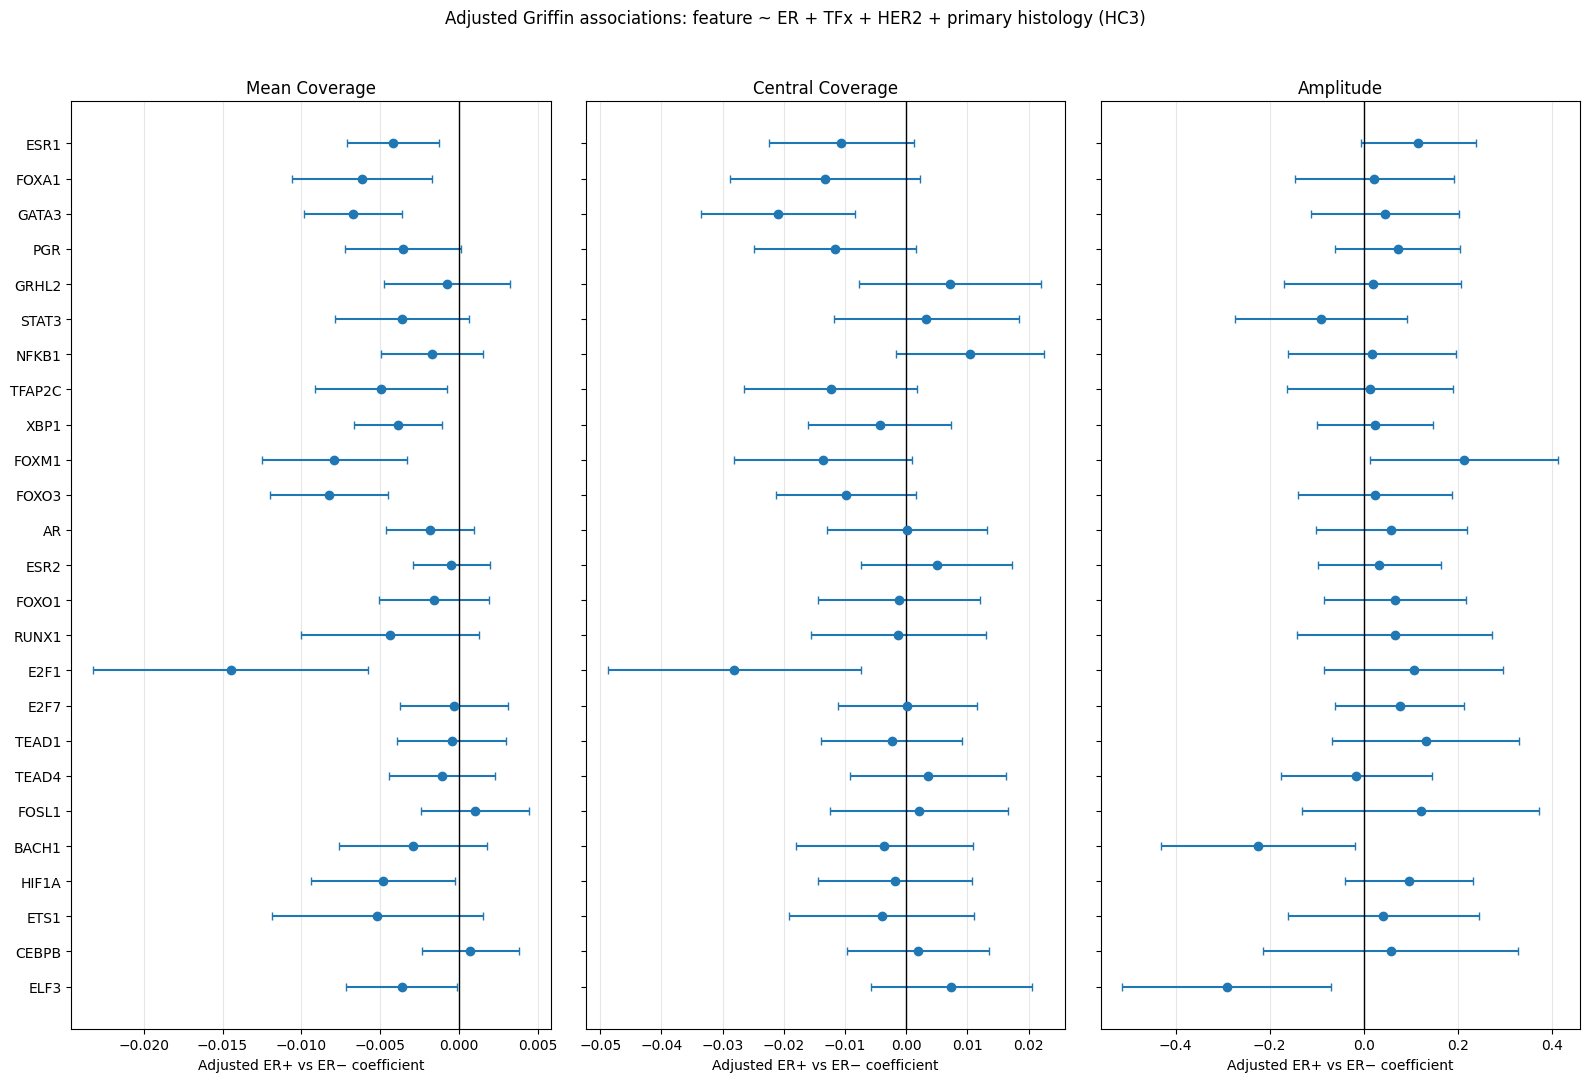

Completed 25-TFBS analysis.
Clinical sheet: AUP_ClinicalData_20260609.NO.DA | TFx sheet: Sheet1
ER_at_first_NB   n
      Positive 166
      Negative  53
       Unknown  43
Output directory: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Met_ER_FirstDraw_TFBS/25_TFBS


In [5]:
#!/usr/bin/env python3
"""AURORA Griffin: first-draw, blood-aligned metastatic ER analysis (25 TFBS).

Primary comparison: ER-positive vs ER-negative using the most recent informative
metastatic ER assessment recorded on or before each patient's lowest-NB cfDNA draw.
Unknown ER cases remain in the audit but are excluded from statistical tests.
"""
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests


# =============================================================================
# CONFIGURATION
# =============================================================================
AURORA_BASE = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")
CLINICAL_FILE = AURORA_BASE / "Clinical_data" / "AUP_ClinicalData_20260609.xlsx"
TFX_FILE = (
    AURORA_BASE / "Clinical_data"
    / "Metasheet_Analysis.with_Histology_Receptor_status.Earliest_Met_Diagnosis.xlsx"
)
GRIFFIN_FILE = (
    AURORA_BASE / "Griffin" / "griffin_nucleosome_profiling"
    / "Griffin_44TF_GC_corrected_summary_by_module.xlsx"
)
OUTDIR = (
    AURORA_BASE / "Griffin" / "Downstream"
    / "AURORA_Griffin_Met_ER_FirstDraw_TFBS" / "25_TFBS"
)
OUTDIR.mkdir(parents=True, exist_ok=True)

TF_ORDER = [
    "ESR1", "FOXA1", "GATA3", "PGR", "GRHL2", "STAT3", "NFKB1", "TFAP2C",
    "XBP1", "FOXM1", "FOXO3", "AR", "ESR2", "FOXO1", "RUNX1", "E2F1",
    "E2F7", "TEAD1", "TEAD4", "FOSL1", "BACH1", "HIF1A", "ETS1", "CEBPB", "ELF3",
]
METRICS = ["mean_coverage", "central_coverage", "amplitude"]
RNG_SEED = 20260824


def clean_id(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    try:
        number = float(text)
        if number.is_integer() and text.replace(".0", "").isdigit():
            return str(int(number))
    except ValueError:
        pass
    return text


def status(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in {"positive", "pos", "+", "er+", "positive (+)", "positive/pos"}:
        return "Positive"
    if text in {"negative", "neg", "-", "er-", "negative (-)", "negative/neg"}:
        return "Negative"
    return np.nan


def histology_category(value):
    if pd.isna(value) or not str(value).strip():
        return np.nan
    text = str(value).lower()
    if ("lobular" in text and "ductal" in text) or "mixed" in text:
        return "Mixed"
    if "lobular" in text:
        return "Lobular"
    if "ductal" in text:
        return "Ductal"
    return "Other"


def find_sheet(path, required_columns):
    """Find an Excel sheet having all required fields (case-sensitive)."""
    with pd.ExcelFile(path) as workbook:
        for sheet in workbook.sheet_names:
            header = pd.read_excel(path, sheet_name=sheet, nrows=0)
            if set(required_columns).issubset(header.columns):
                return sheet
    raise ValueError(f"No worksheet in {path.name} contains: {sorted(required_columns)}")


def read_griffin(path):
    """Read Breast_Lineage sheet; supports the historical row-2 header layout."""
    with pd.ExcelFile(path) as workbook:
        if "Breast_Lineage" not in workbook.sheet_names:
            raise ValueError(f"Breast_Lineage worksheet is missing. Available: {workbook.sheet_names}")
    candidates = [pd.read_excel(path, sheet_name="Breast_Lineage", header=h) for h in (1, 0)]
    expected_feature = f"{TF_ORDER[0]}_{METRICS[0]}"
    for frame in candidates:
        frame.columns = [str(c).strip() for c in frame.columns]
        if expected_feature in frame.columns:
            return frame
    available = candidates[0].columns.tolist()
    raise KeyError(f"Could not locate '{expected_feature}' in Breast_Lineage. First headers: {available[:20]}")


def save_figure(fig, name):
    for extension, kwargs in (("png", {"dpi": 300}), ("pdf", {})):
        fig.savefig(OUTDIR / f"{name}.{extension}", bbox_inches="tight", facecolor="white", **kwargs)
    plt.close(fig)


def fdr_by_metric(results):
    results["q"] = np.nan
    for metric in METRICS:
        index = results.index[(results.metric == metric) & results.p.notna()]
        if len(index):
            results.loc[index, "q"] = multipletests(results.loc[index, "p"], method="fdr_bh")[1]
    return results


def main():
    for file in (CLINICAL_FILE, TFX_FILE, GRIFFIN_FILE):
        if not file.exists():
            raise FileNotFoundError(f"Missing input: {file}")

    # ---- TFx metasheet: select the lowest NB draw per patient. ----
    meta_sheet = find_sheet(TFX_FILE, {"Collaborator_sample_id", "Patient_id", "Tumor_Fraction"})
    meta = pd.read_excel(TFX_FILE, sheet_name=meta_sheet)
    meta["sample"] = (meta["Collaborator_sample_id"].astype(str).str.strip()
                      .str.replace(r"^AUP-", "", regex=True, case=False))
    meta["patient_id"] = meta["Patient_id"].map(clean_id)
    # A single backslash is required: \d means digits in a regular expression.
    # Using r"-NB(\\d+)$" would look for a literal backslash and leaves every NB missing.
    meta["NB"] = pd.to_numeric(meta["sample"].str.extract(r"-NB(\d+)$", flags=re.I)[0], errors="coerce")
    meta = meta.dropna(subset=["patient_id", "NB"]).copy()
    if meta.empty:
        raise ValueError(
            "No usable NB samples were found after parsing Collaborator_sample_id. "
            "Expected IDs ending in -NB<number>, for example AN3U-NB1. "
            "Examples from this file: "
            + ", ".join(first_draw_sample for first_draw_sample in pd.read_excel(TFX_FILE, sheet_name=meta_sheet)["Collaborator_sample_id"].dropna().astype(str).head(10))
        )
    meta["NB"] = meta["NB"].astype(int)
    first_draw = (meta.sort_values(["patient_id", "NB", "sample"])
                  .drop_duplicates("patient_id", keep="first")
                  [["patient_id", "sample", "NB", "Tumor_Fraction"]].copy())
    first_draw["TFx_pct"] = pd.to_numeric(first_draw["Tumor_Fraction"], errors="coerce") * 100

    # ---- Griffin values and feature checks. ----
    griffin = read_griffin(GRIFFIN_FILE)
    sample_column = next((c for c in griffin.columns if c.lower() in {"sample", "sample_id", "barcode"}), griffin.columns[0])
    griffin = griffin.rename(columns={sample_column: "sample"})
    griffin["sample"] = griffin["sample"].astype(str).str.strip().str.replace(r"^AUP-", "", regex=True, case=False)
    features = [f"{tf}_{metric}" for tf in TF_ORDER for metric in METRICS]
    missing_features = [x for x in features if x not in griffin.columns]
    if missing_features:
        raise KeyError("Missing expected 25-TFBS Griffin columns:\n  - " + "\n  - ".join(missing_features))
    griffin = griffin[["sample"] + features].copy()
    griffin[features] = griffin[features].apply(pd.to_numeric, errors="coerce")
    if griffin["sample"].duplicated().any():
        raise ValueError("Griffin file has duplicated sample IDs; resolve before analysis.")

    # ---- Clinical records: attach draw date, receptor status and primary histology. ----
    clinical_sheet = find_sheet(CLINICAL_FILE, {"patient_id", "Category", "Barcode", "Days_From_Primary_Diagnosis", "ER_Status", "PR_Status", "HER2_Status", "Histologic.type"})
    clinical = pd.read_excel(CLINICAL_FILE, sheet_name=clinical_sheet)
    clinical["patient_id"] = clinical["patient_id"].map(clean_id)
    clinical["day"] = pd.to_numeric(clinical["Days_From_Primary_Diagnosis"], errors="coerce")
    clinical["barcode"] = clinical["Barcode"].astype(str).str.strip().str.replace(r"^AUP-", "", regex=True, case=False)
    clinical["ER_norm"] = clinical["ER_Status"].map(status)
    clinical["PR_norm"] = clinical["PR_Status"].map(status)
    clinical["HER2_norm"] = clinical["HER2_Status"].map(status)

    audit_rows = []
    for first in first_draw.itertuples(index=False):
        records = clinical.loc[clinical.patient_id.eq(first.patient_id)].copy()
        blood = records.loc[records.Category.eq("Blood_Draw") & records.barcode.eq(first.sample)].sort_values("day")
        draw_day = blood.day.dropna().iloc[0] if blood.day.notna().any() else np.nan
        metastatic = records.loc[records.Category.eq("Met_Diagnosis") & records.day.notna()].sort_values("day")
        eligible_er = metastatic.loc[metastatic.ER_norm.notna() & metastatic.day.le(draw_day)] if pd.notna(draw_day) else metastatic.iloc[0:0]
        chosen = eligible_er.iloc[-1] if len(eligible_er) else None
        primary = records.loc[records.Category.eq("First_Primary")]
        primary = primary.iloc[0] if len(primary) else None
        row = {
            "patient_id": first.patient_id, "sample": first.sample, "NB": first.NB,
            "draw_day": draw_day, "TFx_pct": first.TFx_pct,
            "ER": chosen.ER_norm if chosen is not None else "Unknown",
            "ER_source_day": chosen.day if chosen is not None else np.nan,
            "ER_lag_days": draw_day - chosen.day if chosen is not None and pd.notna(draw_day) else np.nan,
            "PR": chosen.PR_norm if chosen is not None else np.nan,
            "HER2": chosen.HER2_norm if chosen is not None else np.nan,
            "histology": histology_category(primary["Histologic.type"]) if primary is not None else np.nan,
            "met_records_total": len(metastatic),
            "met_records_known_ER": int(metastatic.ER_norm.notna().sum()),
            "blood_draw_matched": pd.notna(draw_day),
        }
        audit_rows.append(row)
    audit = pd.DataFrame(audit_rows).merge(griffin, on="sample", how="left", validate="one_to_one")
    audit["griffin_matched"] = audit[features].notna().any(axis=1)

    # ---- Welch testing and robust, adjusted linear models. ----
    results = []
    for tf in TF_ORDER:
        for metric in METRICS:
            feature = f"{tf}_{metric}"
            subset = audit.loc[audit.ER.isin(["Positive", "Negative"]) & audit[feature].notna()].copy()
            positive = subset.loc[subset.ER.eq("Positive"), feature].to_numpy(float)
            negative = subset.loc[subset.ER.eq("Negative"), feature].to_numpy(float)
            result = {"TF": tf, "metric": metric, "feature": feature, "n_pos": len(positive), "n_neg": len(negative),
                      "mean_pos": np.mean(positive) if len(positive) else np.nan, "mean_neg": np.mean(negative) if len(negative) else np.nan,
                      "median_pos": np.median(positive) if len(positive) else np.nan, "median_neg": np.median(negative) if len(negative) else np.nan,
                      "diff_mean": np.mean(positive) - np.mean(negative) if len(positive) and len(negative) else np.nan,
                      "welch_p": ttest_ind(positive, negative, equal_var=False).pvalue if len(positive) >= 2 and len(negative) >= 2 else np.nan,
                      "adj_n": 0, "beta_ERpos": np.nan, "se": np.nan, "ci_low": np.nan, "ci_high": np.nan, "p": np.nan, "std_beta": np.nan, "model_status": ""}
            model_data = subset.dropna(subset=["TFx_pct", "HER2", "histology"]).copy()
            model_data = model_data.loc[model_data.HER2.isin(["Positive", "Negative"])]
            result["adj_n"] = len(model_data)
            if len(model_data) < 8 or set(model_data.ER) != {"Positive", "Negative"}:
                result["model_status"] = "Too few complete observations or one ER group"
            else:
                hist = pd.get_dummies(model_data.histology, prefix="hist", drop_first=True, dtype=float)
                X = pd.concat([pd.Series(1.0, index=model_data.index, name="intercept"),
                               model_data.ER.eq("Positive").astype(float).rename("ER_positive"),
                               model_data.TFx_pct.astype(float), model_data.HER2.eq("Positive").astype(float).rename("HER2_positive"), hist], axis=1)
                if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
                    result["model_status"] = "Rank-deficient design"
                else:
                    fit = sm.OLS(model_data[feature].astype(float), X).fit(cov_type="HC3")
                    ci = fit.conf_int().loc["ER_positive"]
                    y_sd = model_data[feature].std(ddof=1)
                    result.update({"beta_ERpos": fit.params.ER_positive, "se": fit.bse.ER_positive,
                                   "ci_low": ci.iloc[0], "ci_high": ci.iloc[1], "p": fit.pvalues.ER_positive,
                                   "std_beta": fit.params.ER_positive / y_sd if y_sd > 0 else np.nan, "model_status": "OK"})
            results.append(result)
    results = fdr_by_metric(pd.DataFrame(results))

    # ---- Outputs. ----
    audit_columns = ["patient_id", "sample", "NB", "draw_day", "ER", "ER_source_day", "ER_lag_days", "TFx_pct", "PR", "HER2", "histology", "met_records_total", "met_records_known_ER", "griffin_matched", "blood_draw_matched"] + features
    audit = audit[audit_columns].sort_values(["ER", "patient_id", "sample"])
    audit.to_csv(OUTDIR / "First_draw_blood_aligned_metastatic_ER_dataset_25TFBS.tsv", sep="\t", index=False)
    results.to_csv(OUTDIR / "TFBS_25TFBS_ER_comparison_full_results.tsv", sep="\t", index=False)
    counts = audit.ER.value_counts().reindex(["Positive", "Negative", "Unknown"], fill_value=0).rename_axis("ER_at_first_NB").reset_index(name="n")

    # Five-by-five panels, one figure per feature family.
    for metric in METRICS:
        fig, axes = plt.subplots(5, 5, figsize=(18, 17))
        for i, (tf, ax) in enumerate(zip(TF_ORDER, axes.flat)):
            feature = f"{tf}_{metric}"
            neg = audit.loc[audit.ER.eq("Negative"), feature].dropna().to_numpy(float)
            pos = audit.loc[audit.ER.eq("Positive"), feature].dropna().to_numpy(float)
            # `labels` works with the Matplotlib version in the current conda environment.
            ax.boxplot([neg, pos], labels=[f"ER−\nn={len(neg)}", f"ER+\nn={len(pos)}"], showfliers=False, widths=.58)
            generator = np.random.default_rng(RNG_SEED + i)
            for x, values in enumerate((neg, pos), 1):
                ax.scatter(generator.normal(x, .055, len(values)), values, s=10, alpha=.36, linewidths=0)
            res = results.loc[(results.TF == tf) & (results.metric == metric)].iloc[0]
            qtext = "q=NA" if pd.isna(res.q) else f"q={res.q:.3g}"
            ax.set_title(f"{tf}\nβ={res.beta_ERpos:.4g}; {qtext}", fontsize=9)
            ax.tick_params(labelsize=7); ax.grid(axis="y", alpha=.25, linewidth=.4)
        fig.suptitle(f"25 breast-lineage TFBS: {metric.replace('_', ' ').title()} by metastatic ER status\nFirst NB; ER aligned to most recent informative metastatic assessment on/before draw", y=.995)
        fig.tight_layout(rect=(0, 0, 1, .96))
        plt.show()
        save_figure(fig, f"Faceted_25TFBS_{metric}_ER_positive_vs_negative")

    # Adjusted forest plot.
    fig, axes = plt.subplots(1, 3, figsize=(16, 11), sharey=True)
    y = np.arange(len(TF_ORDER))
    for ax, metric in zip(axes, METRICS):
        dat = results.loc[results.metric.eq(metric)].set_index("TF").loc[TF_ORDER]
        beta, low, high = dat.beta_ERpos.to_numpy(float), dat.ci_low.to_numpy(float), dat.ci_high.to_numpy(float)
        valid = np.isfinite(beta) & np.isfinite(low) & np.isfinite(high)
        ax.errorbar(beta[valid], y[valid], xerr=np.vstack([beta[valid]-low[valid], high[valid]-beta[valid]]), fmt="o", capsize=3)
        ax.axvline(0, color="black", lw=1); ax.set_title(metric.replace("_", " ").title()); ax.set_xlabel("Adjusted ER+ vs ER− coefficient"); ax.grid(axis="x", alpha=.3)
        ax.set_yticks(y); ax.set_yticklabels(TF_ORDER); ax.invert_yaxis()
    fig.suptitle("Adjusted Griffin associations: feature ~ ER + TFx + HER2 + primary histology (HC3)", y=.98)
    fig.tight_layout(rect=(0, 0, 1, .96)); plt.show(); save_figure(fig, "Faceted_adjusted_forest_all_25_TFBS")

    with pd.ExcelWriter(OUTDIR / "AURORA_Griffin_Met_ER_FirstDraw_25TFBS_results.xlsx") as writer:
        pd.DataFrame({"Item": ["Feature collections", "TFBS collections", "ER source", "First-draw rule", "Adjusted model", "FDR"],
                      "Value": ["25 breast-lineage TFBS", ", ".join(TF_ORDER), "Most recent informative Met_Diagnosis ER on/before selected draw", "Lowest NB per patient", "feature ~ ER + TFx + HER2 + primary histology; HC3 robust SE", "BH within each 25-TF metric family"]}).to_excel(writer, sheet_name="README", index=False)
        counts.to_excel(writer, sheet_name="Cohort_counts", index=False)
        results.to_excel(writer, sheet_name="TFBS_results", index=False)
        audit.to_excel(writer, sheet_name="Patient_audit", index=False)
        results.loc[results.q.lt(.05)].to_excel(writer, sheet_name="FDR_significant", index=False)

    print("Completed 25-TFBS analysis.")
    print("Clinical sheet:", clinical_sheet, "| TFx sheet:", meta_sheet)
    print(counts.to_string(index=False))
    print("Output directory:", OUTDIR)


if __name__ == "__main__":
    main()